In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
units = pd.read_csv("units_L234.csv").copy()  # Load the neuron table into a pandas DataFrame

print(units["strategy_axon"].value_counts(dropna=False))
print(units["strategy_dendrite"].value_counts(dropna=False))

strategy_axon
none                       23799
axon_partially_extended      916
axon_fully_extended           43
axon_interareal               13
Name: count, dtype: int64
strategy_dendrite
none                 23795
dendrite_extended      498
dendrite_clean         478
Name: count, dtype: int64


In [3]:
def clean_dataset(units):

    mask_layer = ((units['layer'] == 'L2/3') | (units['layer'] == 'L4'))
    mask_area = (units['brain_area'] == 'V1')
    mask = mask_area & mask_layer

    data = units[mask].copy()
    data = data.drop(columns=['pvals_ori_fdr', 'pvals_dir_fdr', 'brain_area'])
    data['pt_root_id'] = data['pt_root_id'].astype(np.int64)

    for c in ['pt_position_x', 'pt_position_y', 'pt_position_z']:
        data[c] = data[c].astype(np.float32)

    return data

selected_mask (6397, 11)


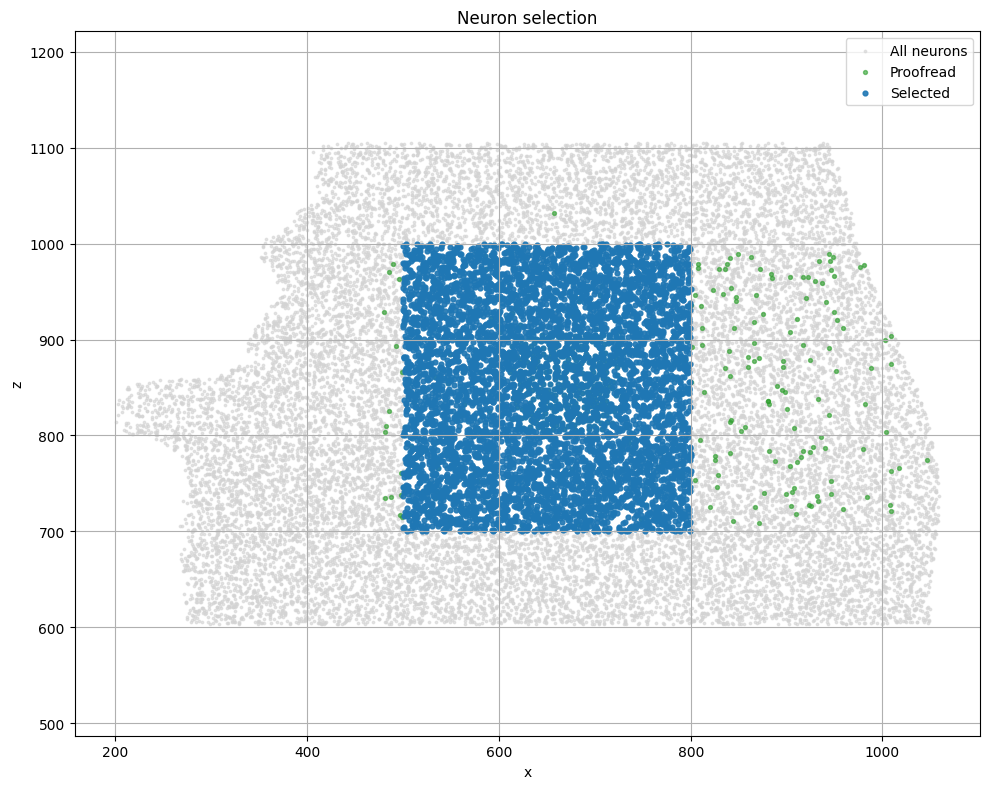

In [4]:
units_cleaned = clean_dataset(units)

proofread = units_cleaned[(units_cleaned['strategy_axon'] != 'none')] 
# Keep neurons whose axon has undergone proofreading

selected_mask = units_cleaned[
    (units_cleaned["pt_position_z"] < 1000)
    & (units_cleaned["pt_position_z"] > 700)
    & (units_cleaned["pt_position_x"] > 500)
    & (units_cleaned["pt_position_x"] < 800)
]

print("selected_mask", selected_mask.shape)

plt.figure(figsize=(10, 8))

# 1. Tout le connectome
plt.scatter(
    units["pt_position_x"],
    units["pt_position_z"],
    s=3,
    alpha=0.6,
    color="lightgray",
    label=f"All neurons"
)

# 2. Neurones proofread
plt.scatter(
    proofread["pt_position_x"],
    proofread["pt_position_z"],
    s=8,
    alpha=0.6,
    color="tab:green",
    label=f"Proofread"
)

# 3. Neurones finalement sélectionnés
plt.scatter(
    selected_mask["pt_position_x"],
    selected_mask["pt_position_z"],
    s=12,
    alpha=0.9,
    color="tab:blue",
    label=f"Selected"
)

plt.xlabel("x")
plt.ylabel("z")

plt.title(
    f"Neuron selection"
)

plt.axis("equal")
plt.grid(True)
plt.legend()

plt.tight_layout()

plt.tight_layout()

In [5]:
mask_exc = (selected_mask['classification_system'] == 'excitatory_neuron')
mask_inh = (selected_mask['classification_system'] == 'inhibitory_neuron')

mask_l23 = (selected_mask['layer'] == 'L2/3')
mask_l4 = (selected_mask['layer'] == 'L4')

In [6]:
E_L23 = selected_mask[mask_exc & mask_l23].copy().reset_index(drop=True)
print(E_L23.shape)
I_L23 = selected_mask[mask_inh & mask_l23].copy().reset_index(drop=True)
E_L4 = selected_mask[mask_exc & mask_l4].copy().reset_index(drop=True)
I_L4 = selected_mask[mask_inh & mask_l4].copy().reset_index(drop=True)

print(E_L23)

(3398, 11)
              pt_root_id  pt_position_x  pt_position_y  pt_position_z  \
0     864691135275621605     524.797852     223.267166     719.960022   
1     864691135738006641     501.233734     104.152145     960.080017   
2     864691135754570189     534.967834     225.249084     904.119995   
3     864691135763941174     613.394775     104.264053     927.880005   
4     864691136488446226     547.738770     131.413071     711.880005   
...                  ...            ...            ...            ...   
3393  864691136238038799     708.155273     187.977524     799.599976   
3394  864691135778700477     661.907227     120.329323     830.760010   
3395  864691135492080871     650.922607     107.097603     847.359985   
3396  864691135865698780     766.132935     117.883888     999.400024   
3397  864691136195316456     640.180115      76.412567     998.919983   

     classification_system  strategy_dendrite            strategy_axon layer  \
0        excitatory_neuron  dend

In [7]:
pathways = [
    # post = E_L23

    ('E23_E23', E_L23, E_L23),
    ('I23_E23', I_L23, E_L23),
    ('E4_E23', E_L4, E_L23),
    ('I4_E23', I_L4, E_L23),

    # post = I_L23s

    ('E23_I23', E_L23, I_L23),
    ('I23_I23', I_L23, I_L23),
    ('E4_I23', E_L4, I_L23),
    ('I4_I23', I_L4, I_L23),
]


path_syn = 'synapses_L234.csv'
synapses = pd.read_csv(f'{path_syn}').copy()
mean_syn_size = synapses['size'].mean()
synapses['size'] /= mean_syn_size

In [8]:
def circular_diff_ori(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    diff = (a - b + np.pi / 2) % np.pi - np.pi / 2
    return diff.astype(np.float32)

In [9]:
def polar_distance(theta1,theta2):
    return np.sqrt((np.cos(2*theta1)-np.cos(2*theta2))**2+ (np.sin(2*theta1)-np.sin(2*theta2))**2)

In [10]:
def existing_connections_v1(
    pre_pop, post_pop,
    syn, metric=['Euclidean', 'Ori_Diff']
):
    

    """mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy().reset_index(drop=True)"""

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z',
    ]

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    pre_pop = pre_pop[feat_to_keep].copy()
    post_pop = post_pop[feat_to_keep].copy()

    pre_pop = pre_pop.rename(columns=lambda x: f"pre_{x}")
    post_pop = post_pop.rename(columns=lambda x: f"post_{x}")

    mask_syn_pre = syn['pre_pt_root_id'].isin(pre_pop['pre_pt_root_id'])
    mask_syn_post = syn['post_pt_root_id'].isin(post_pop['post_pt_root_id'])

    syn = syn[mask_syn_pre & mask_syn_post].copy().reset_index(drop=True)

    conn = syn.merge(pre_pop, on='pre_pt_root_id').merge(post_pop, on='post_pt_root_id')

    # Remove self-connections
    conn = conn[
        conn['pre_pt_root_id'] != conn['post_pt_root_id']
    ].reset_index(drop=True)

    dx = conn['pre_pt_position_x'].to_numpy() - conn['post_pt_position_x'].to_numpy()
    dz = conn['pre_pt_position_z'].to_numpy() - conn['post_pt_position_z'].to_numpy()

    """conn = conn.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])"""
    if 'Euclidean' in metric:
        dy = conn['pre_pt_position_y'].to_numpy() - conn['post_pt_position_y'].to_numpy()
        #conn = conn.drop(columns=['pre_pt_position_y', 'post_pt_position_y'])
        conn['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        conn['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = conn['pre_pref_ori_fit'].to_numpy()
        ori_post = conn['post_pref_ori_fit'].to_numpy()

        conn['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        conn['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    return conn

In [11]:
AXON_CATEGORIES = [
    "none",
    "axon_partially_extended",
    "axon_fully_extended",
    "axon_interareal",
]

DENDRITE_CATEGORIES = [
    "none",
    "dendrite_extended",
    "dendrite_clean",
]

AXON_TO_INDEX = {
    name: index
    for index, name in enumerate(AXON_CATEGORIES)
}

DENDRITE_TO_INDEX = {
    name: index
    for index, name in enumerate(DENDRITE_CATEGORIES)
}

In [12]:
def potential_connections_v1(pre_pop, post_pop, metric = ['Euclidean']):

    """mask_proof = pre_pop['strategy_axon'] != 'none'
    pre_pop = pre_pop[mask_proof].copy()"""

    feat_to_keep = [
        'pt_root_id',
        'pt_position_x',
        'pt_position_z'
    ]

    if 'Euclidean' in metric:
        feat_to_keep.append('pt_position_y')

    if 'Ori_Diff' in metric:
        mask_sel_pre = pre_pop['selective_ori'] == 'True'
        mask_sel_post = post_pop['selective_ori'] == 'True'
        
        pre_pop = pre_pop[mask_sel_pre].copy().reset_index(drop=True)
        post_pop = post_pop[mask_sel_post].copy().reset_index(drop=True)

        feat_to_keep.append('pref_ori_fit')

    pre = pre_pop[feat_to_keep].copy().rename(columns=lambda x: f"pre_{x}")
    post = post_pop[feat_to_keep].copy().rename(columns=lambda x: f"post_{x}")

    # Cartesian product
    all_pairs = (
        pre.assign(key=1)
        .merge(post.assign(key=1), on='key')
        .drop(columns='key')
    )

    # Remove self-connections
    all_pairs = all_pairs[
        all_pairs['pre_pt_root_id'] != all_pairs['post_pt_root_id']
    ].reset_index(drop=True)

    dx = all_pairs['pre_pt_position_x'] - all_pairs['post_pt_position_x']
    dz = all_pairs['pre_pt_position_z'] - all_pairs['post_pt_position_z']

    """all_pairs = all_pairs.drop(columns=[
        'pre_pt_position_x', 'pre_pt_position_z',
        'post_pt_position_x', 'post_pt_position_z'
    ])"""

    if 'Euclidean' in metric:
        dy = all_pairs['pre_pt_position_y'] - all_pairs['post_pt_position_y']
        all_pairs['euclidean'] = np.sqrt(dx**2 + dy**2 + dz**2)
    else:
        all_pairs['lateral'] = np.sqrt(dx**2 + dz**2)

    if 'Ori_Diff' in metric:
        ori_pre = all_pairs['pre_pref_ori_fit'].to_numpy()
        ori_post = all_pairs['post_pref_ori_fit'].to_numpy()

        all_pairs['ori_diff'] = circular_diff_ori(ori_pre, ori_post)
        all_pairs['ori_diff_polar'] = polar_distance(ori_pre, ori_post)

    all_pairs['size'] = 0.0

    return all_pairs


In [13]:
def build_dataset(
    pre_pop,
    post_pop,
    synapses,
    metric=["Euclidean"]
):
    """
    Build the potential neuron pairs and their connection labels.

    Returns:
    - raw pair features
    - connection labels
    - neuron indices
    - raw neuron positions in µm
    - global distance normalization parameters
    - normalized neuron positions
    - proofreading features
    """

    # ========================================================
    # Existing and potential connections
    # ========================================================

    conn_dist = existing_connections_v1(
        pre_pop,
        post_pop,
        synapses,
        metric
    ).copy()

    pot_dist = potential_connections_v1(
        pre_pop,
        post_pop,
        metric
    ).copy()

    print(
        "Existing connections:",
        len(conn_dist)
    )

    print(
        "Potential pairs:",
        len(pot_dist)
    )

    conn_dist["label"] = 1
    pot_dist["label"] = 0

    # Existing connections are placed first so that
    # they are kept when duplicates are removed.

    df = pd.concat(
        [
            conn_dist,
            pot_dist,
        ],
        ignore_index=True
    )

    df = (
        df
        .drop_duplicates(
            subset=[
                "pre_pt_root_id",
                "post_pt_root_id",
            ],
            keep="first"
        )
        .reset_index(drop=True)
    )

    print(
        "Number of unique pairs:",
        len(df)
    )

    # ========================================================
    # Neuron ID mapping
    # ========================================================


    all_ids = pd.Index(
        pd.concat(
            [
                df["pre_pt_root_id"],
                df["post_pt_root_id"],
            ]
        ).unique()
    )

    id_map = {
        neuron_id: index
        for index, neuron_id in enumerate(all_ids)
    }

    pre_idx = (
        df["pre_pt_root_id"]
        .map(id_map)
        .to_numpy(dtype=np.int64)
    )

    post_idx = (
        df["post_pt_root_id"]
        .map(id_map)
        .to_numpy(dtype=np.int64)
    )

    # ========================================================
    # Neuron positions
    # ========================================================

    id_to_pos = (
        units_cleaned
        .drop_duplicates("pt_root_id")
        .set_index("pt_root_id")
        [
            [
                "pt_position_x",
                "pt_position_y",
                "pt_position_z",
            ]
        ]
    )

    # Raw positions in µm.
    # These positions must be used to calculate distance.

    positions_um = (
        id_to_pos
        .loc[np.asarray(all_ids)]
        .to_numpy(dtype=np.float32)
    )

    # Axis-wise normalized positions.
    # These can be used as inputs of P(connection),
    # but must not be used to calculate physical distance.

    positions = (
        positions_um
        - positions_um.mean(
            axis=0,
            keepdims=True
        )
    ) / (
        positions_um.std(
            axis=0,
            keepdims=True
        )
        + 1e-8
    )

    # ========================================================
    # Global scalar distance normalization
    # ========================================================

    if "euclidean" not in df.columns:
        raise ValueError(
            "The Euclidean distance is required. "
            "Use metric=['Euclidean']."
        )

    distance_mean = np.float32(
        df["euclidean"].mean()
    )

    distance_std = np.float32(
        df["euclidean"].std(
            ddof=0
        )
        + 1e-8
    )

    print(
        f"Distance mean: {distance_mean:.2f} µm"
    )

    print(
        f"Distance std: {distance_std:.2f} µm"
    )

    # ========================================================
    # Proofreading information
    # Ordered exactly like all_ids
    # ========================================================

    neuron_metadata = (
        units_cleaned
        .drop_duplicates("pt_root_id")
        .set_index("pt_root_id")
        .reindex(np.asarray(all_ids))
    )

    axon_labels = (
        neuron_metadata["strategy_axon"]
        .fillna("none")
        .astype(str)
        .to_numpy()
    )

    dendrite_labels = (
        neuron_metadata["strategy_dendrite"]
        .fillna("none")
        .astype(str)
        .to_numpy()
    )

    axon_indices = np.array(
        [
            AXON_TO_INDEX.get(
                label,
                AXON_TO_INDEX["none"]
            )
            for label in axon_labels
        ],
        dtype=np.int64
    )

    dendrite_indices = np.array(
        [
            DENDRITE_TO_INDEX.get(
                label,
                DENDRITE_TO_INDEX["none"]
            )
            for label in dendrite_labels
        ],
        dtype=np.int64
    )

    axon_features = np.eye(
        len(AXON_CATEGORIES),
        dtype=np.float32
    )[axon_indices]

    dendrite_features = np.eye(
        len(DENDRITE_CATEGORIES),
        dtype=np.float32
    )[dendrite_indices]

    # ========================================================
    # Fully proofread definitions
    # ========================================================

    axon_fully_proofread = (
        axon_labels
        == "axon_fully_extended"
    )

    dendrite_fully_proofread = (
        dendrite_labels
        == "dendrite_clean"
    )

    # ========================================================
    # Pair features and labels
    # ========================================================

    features = [
        "pre_pt_position_x",
        "pre_pt_position_y",
        "pre_pt_position_z",
        "post_pt_position_x",
        "post_pt_position_y",
        "post_pt_position_z",
    ]

    X = df[features].to_numpy(
        dtype=np.float32
    )

    y = df["label"].to_numpy(
        dtype=np.float32
    )

    # ========================================================
    # Return
    # ========================================================

    return (
        X,
        y,
        features,
        pre_idx,
        post_idx,
        positions_um,
        distance_mean,
        distance_std,
        positions,
        axon_features,
        dendrite_features,
        axon_fully_proofread,
        dendrite_fully_proofread,
    )

In [14]:
path, pre, post = pathways[0]
print(pre)
( _,
    y,
    _,
    pre_idx,
    post_idx,
    positions_um,
    distance_mean,
    distance_std,
    positions,
    axon_features,
    dendrite_features,
    axon_fully_proofread,
    dendrite_fully_proofread,
) = build_dataset(
    pre,
    post,
    synapses,
    metric=["Euclidean"]
)

              pt_root_id  pt_position_x  pt_position_y  pt_position_z  \
0     864691135275621605     524.797852     223.267166     719.960022   
1     864691135738006641     501.233734     104.152145     960.080017   
2     864691135754570189     534.967834     225.249084     904.119995   
3     864691135763941174     613.394775     104.264053     927.880005   
4     864691136488446226     547.738770     131.413071     711.880005   
...                  ...            ...            ...            ...   
3393  864691136238038799     708.155273     187.977524     799.599976   
3394  864691135778700477     661.907227     120.329323     830.760010   
3395  864691135492080871     650.922607     107.097603     847.359985   
3396  864691135865698780     766.132935     117.883888     999.400024   
3397  864691136195316456     640.180115      76.412567     998.919983   

     classification_system  strategy_dendrite            strategy_axon layer  \
0        excitatory_neuron  dendrite_extend

In [15]:
import os
import json
import numpy as np
import torch
import torch.nn as nn

from torch.utils.data import (
    TensorDataset,
    DataLoader,
    random_split,
)

from sklearn.metrics import roc_auc_score


# ============================================================
# Hardware
# ============================================================

# Use the GPU when CUDA is available, otherwise use the CPU.
DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", DEVICE)
print("torch version:", torch.__version__)
print("cuda available:", torch.cuda.is_available())
print("torch cuda version:", torch.version.cuda)
print("device count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print(
        "gpu:",
        torch.cuda.get_device_name(0),
    )


# ============================================================
# Checkpoints
# ============================================================

# All checkpoints and training results will be saved here.
# Use a new directory whenever the model architecture changes,
# otherwise an old incompatible checkpoint may be loaded.
CHECKPOINT_DIR = os.path.join(
    "checkpoints_embedding_LP_3dgeoV3_gesture_proofread_distance" \
    "_30_epoch_5_patience_2_hidden_layers_of_32_neurons_Relu_in_between_bce_simple"
)

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True,
)


# ============================================================
# Training configuration
# ============================================================

# Number of neuron pairs processed at once.
# Reduce this value if the GPU runs out of memory.
BATCH_SIZE = 32768

# Maximum number of training epochs.
N_EPOCHS = 100

# Stop training after 10 epochs without improvement.
PATIENCE = 10

# Adam learning rate.
LR = 1e-3

# Latent dimensions to train and compare.
DIMS = [1,2,3,4,5]


# ============================================================
# Dataset split
# ============================================================

# 80% training, 10% validation and 10% final testing.
TRAIN_FRAC = 0.8
VAL_FRAC = 0.1
TEST_FRAC = 0.1

# ============================================================
# Reproducibility
# ============================================================

# Fix the random generators to obtain reproducible splits
# and similar model initializations between runs.
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

Device: cuda
torch version: 2.11.0+cu128
cuda available: True
torch cuda version: 12.8
device count: 1
gpu: NVIDIA GeForce RTX 5070 Ti Laptop GPU


In [16]:
import torch
import torch.nn as nn


class VisibilityAwareEmbeddingModel(nn.Module):

    def __init__(
        self,
        n_neurons,
        dim,
        positions,
        positions_um,
        distance_mean,
        distance_std,
        axon_features,
        dendrite_features,
        axon_fully_proofread,
        dendrite_fully_proofread,
        hidden_connection=64,
        hidden_error=32,
    ):
        super().__init__()

        self.dim = dim

        # ====================================================
        # Latent embedding
        # ====================================================

        self.Z = nn.Embedding(
            n_neurons,
            dim
        )

        nn.init.normal_(
            self.Z.weight,
            mean=0.0,
            std=0.1
        )

        # ====================================================
        # Fixed neuron information
        # ====================================================

        # Axis-wise normalized positions for P(connection)

        self.register_buffer(
            "positions",
            torch.as_tensor(
                positions,
                dtype=torch.float32
            )
        )

        # True positions in µm for P(error)

        self.register_buffer(
            "positions_um",
            torch.as_tensor(
                positions_um,
                dtype=torch.float32
            )
        )

        # Scalar distance normalization

        self.register_buffer(
            "distance_mean",
            torch.as_tensor(
                distance_mean,
                dtype=torch.float32
            )
        )

        self.register_buffer(
            "distance_std",
            torch.as_tensor(
                distance_std,
                dtype=torch.float32
            )
        )

        self.register_buffer(
            "axon_features",
            torch.as_tensor(
                axon_features,
                dtype=torch.float32
            )
        )

        self.register_buffer(
            "dendrite_features",
            torch.as_tensor(
                dendrite_features,
                dtype=torch.float32
            )
        )

        self.register_buffer(
            "axon_fully_proofread",
            torch.as_tensor(
                axon_fully_proofread,
                dtype=torch.bool
            )
        )

        self.register_buffer(
            "dendrite_fully_proofread",
            torch.as_tensor(
                dendrite_fully_proofread,
                dtype=torch.bool
            )
        )

        # ====================================================
        # P(connection)
        #
        # Inputs:
        # - normalized pre position: 3
        # - pre latent variables: dim
        # - normalized post position: 3
        # - post latent variables: dim
        # ====================================================

        neuron_feature_dim = 3
        connection_input_dim = 2 * neuron_feature_dim

        self.connection_mlp = nn.Sequential(
            nn.Linear(
                connection_input_dim,
                hidden_connection
            ),
            nn.ReLU(),
            nn.Linear(
                hidden_connection,
                1
            )
        )

        # ====================================================
        # P(error)
        #
        # Inputs:
        # - normalized physical distance: 1
        # - pre axon category
        # - post dendrite category
        # ====================================================

        error_input_dim = (
            1
            + len(AXON_CATEGORIES)
        )

        self.error_mlp = nn.Sequential(
            nn.Linear(
                error_input_dim,
                hidden_error
            ),
            nn.ReLU(),
            nn.Linear(
                hidden_error,
                1
            )
        )

        # Initially predict a small error probability

        nn.init.constant_(
            self.error_mlp[-1].bias,
            -3.0
        )

    def forward_components(
        self,
        pre_idx,
        post_idx
    ):

        # ====================================================
        # Positions
        # ====================================================

        # Normalized positions for P(connection)

        pos_pre = self.positions[pre_idx]
        pos_post = self.positions[post_idx]

        # True positions in µm for P(error)

        pos_pre_um = self.positions_um[pre_idx]
        pos_post_um = self.positions_um[post_idx]

        # ====================================================
        # 1. True connection probability
        # ====================================================

        z_pre = self.Z(pre_idx)
        z_post = self.Z(post_idx)

        h_pre = torch.cat(
            [
                pos_pre
            ],
            dim=1
        )

        h_post = torch.cat(
            [
                pos_post
            ],
            dim=1
        )

        connection_input = torch.cat(
            [
                h_pre,
                h_post,
            ],
            dim=1
        )

        connection_logits = (
            self.connection_mlp(
                connection_input
            )
            .squeeze(1)
        )

        p_connection = torch.sigmoid(
            connection_logits
        )

        # ====================================================
        # 2. Error probability
        # ====================================================

        axon_pre = self.axon_features[
            pre_idx
        ]

        dendrite_post = self.dendrite_features[
            post_idx
        ]

        # True physical distance in µm

        distance_um = torch.linalg.vector_norm(
            pos_pre_um - pos_post_um,
            dim=1
        )

        # Scalar centered and reduced distance

        distance = (
            distance_um
            - self.distance_mean
        ) / self.distance_std

        distance = distance.unsqueeze(1)

        error_input = torch.cat(
            [
                distance,
                axon_pre
            ],
            dim=1
        )

        error_logits = (
            self.error_mlp(
                error_input
            )
            .squeeze(1)
        )

        p_error_raw = torch.sigmoid(
            error_logits
        )

        # ====================================================
        # Hard constraint
        #
        # Fully proofread axon AND clean dendrite:
        # P(error) = 0
        # ====================================================

        fully_proofread_pair = (
            self.axon_fully_proofread[pre_idx]
        )

        p_error = torch.where(
            fully_proofread_pair,
            torch.zeros_like(
                p_error_raw
            ),
            p_error_raw
        )

        p_visible = 1.0 - p_error

        # ====================================================
        # Observed connection probability
        # ====================================================

        p_observed = (
            p_connection
            * p_visible
        )

        p_observed = torch.clamp(
            p_observed,
            min=1e-7,
            max=1.0 - 1e-7
        )

        return {
            "p_observed": p_observed,
            "p_connection": p_connection,
            "p_visible": p_visible,
            "p_error": p_error,
            "distance_um": distance_um,
            "distance_normalized": distance.squeeze(1),
            "fully_proofread_pair": fully_proofread_pair,
        }

    def forward(
        self,
        pre_idx,
        post_idx
    ):

        return self.forward_components(
            pre_idx,
            post_idx
        )["p_observed"]

In [17]:
# =========================
# Data
# =========================

(
    _,
    y,
    _,
    pre_idx,
    post_idx,
    positions_um,
    distance_mean,
    distance_std,
    positions,
    axon_features,
    dendrite_features,
    axon_fully_proofread,
    dendrite_fully_proofread,
) = build_dataset(
    pre,
    post,
    synapses,
    metric=["Euclidean"]
)

y = torch.tensor(y, dtype=torch.float32)
pre_idx = torch.tensor(pre_idx, dtype=torch.long)
post_idx = torch.tensor(post_idx, dtype=torch.long)

n_neurons = int(max(pre_idx.max(), post_idx.max()).item()) + 1
print("n_neurons:", n_neurons)
print("n_pairs:", len(y))
print("positive rate:", y.mean().item())

pre_idx = pre_idx.to(DEVICE)
post_idx = post_idx.to(DEVICE)
y = y.to(DEVICE)

dataset = TensorDataset(pre_idx, post_idx, y)

n_total = len(dataset)
n_train = int(TRAIN_FRAC * n_total)
n_val = int(VAL_FRAC * n_total)
n_test = n_total - n_train - n_val

train_set, val_set, test_set = random_split(
    dataset,
    [n_train, n_val, n_test],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False)

Existing connections: 100040
Potential pairs: 11543006
Number of unique pairs: 11543006
Distance mean: 174.10 µm
Distance std: 70.22 µm
n_neurons: 3398
n_pairs: 11543006
positive rate: 0.008666720241308212


In [18]:
def evaluate(model, loader, criterion):

    model.eval()

    total_loss = 0.0
    all_y = []
    all_predictions = []

    with torch.no_grad():

        for pi, pj, yb in loader:

            p_observed = model(pi, pj)

            loss = criterion(
                p_observed,
                yb
            )

            total_loss += (
                loss.item() * len(yb)
            )

            all_y.append(
                yb.cpu().numpy()
            )

            all_predictions.append(
                p_observed.cpu().numpy()
            )

    all_y = np.concatenate(all_y)
    all_predictions = np.concatenate(
        all_predictions
    )

    auc = roc_auc_score(
        all_y,
        all_predictions
    )

    return (
        total_loss / len(loader.dataset),
        auc
    )

In [19]:
def save_checkpoint(
    path,
    model,
    optimizer,
    dim,
    epoch,
    best_val_loss,
    best_val_auc,
    best_epoch,
    results,
    epochs_without_improvement=0
):
    torch.save({
        "dim": dim,
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),

        # Best metrics
        "best_val_loss": best_val_loss,
        "best_val_auc": best_val_auc,
        "best_epoch": best_epoch,

        # Early stopping state
        "epochs_without_improvement": epochs_without_improvement,

        # Saved results
        "results": results,

        # RNG states for reproducibility
        "rng_state": torch.get_rng_state(),
        "cuda_rng_state": (
            torch.cuda.get_rng_state_all()
            if torch.cuda.is_available()
            else None
        ),
        "numpy_rng_state": np.random.get_state(),
    }, path)


def load_checkpoint(path, model, optimizer):
    ckpt = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False
    )

    # Restore model and optimizer
    model.load_state_dict(ckpt["model_state_dict"])
    optimizer.load_state_dict(ckpt["optimizer_state_dict"])

    # Restore CPU RNG state if compatible
    rng_state = ckpt.get("rng_state", None)
    if (
        isinstance(rng_state, torch.Tensor)
        and rng_state.dtype == torch.uint8
    ):
        try:
            torch.set_rng_state(rng_state.cpu())
        except Exception as e:
            print("Warning: CPU rng_state ignored:", e)
    else:
        print("Warning: CPU rng_state ignored.")

    # Restore CUDA RNG state if compatible
    cuda_rng_state = ckpt.get("cuda_rng_state", None)
    if (
        torch.cuda.is_available()
        and isinstance(cuda_rng_state, list)
    ):
        try:
            torch.cuda.set_rng_state_all(cuda_rng_state)
        except Exception as e:
            print("Warning: CUDA rng_state ignored:", e)

    # Restore NumPy RNG state if compatible
    numpy_rng_state = ckpt.get("numpy_rng_state", None)
    if numpy_rng_state is not None:
        try:
            np.random.set_state(numpy_rng_state)
        except Exception as e:
            print("Warning: NumPy rng_state ignored:", e)

    return ckpt

In [20]:
import os

dim = 1  # change selon la dimension qui plante
"""bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")

if os.path.exists(bad_path):
    os.remove(bad_path)
    print("Deleted:", bad_path)"""

'bad_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")\n\nif os.path.exists(bad_path):\n    os.remove(bad_path)\n    print("Deleted:", bad_path)'

In [65]:
import csv

log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

# Créer le fichier avec en-tête s'il n'existe pas
if not os.path.exists(log_csv_path):
    with open(log_csv_path, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            "dim",
            "epoch",
            "train_loss",
            "val_loss",
            "val_auc"
        ])

In [66]:
# =========================
# Result / Training
# =========================

results_path = os.path.join(CHECKPOINT_DIR, "summary_results.json")

if os.path.exists(results_path):
    with open(results_path, "r") as f:
        results = json.load(f)
else:
    results = []


for dim in DIMS:
    print(f"\n====================")
    print(f"Training dim = {dim}")
    print(f"====================")

    last_ckpt_path = os.path.join(CHECKPOINT_DIR, f"last_dim_{dim}.pt")
    best_ckpt_path = os.path.join(CHECKPOINT_DIR, f"best_dim_{dim}.pt")
    log_csv_path = os.path.join(CHECKPOINT_DIR, f"training_log_dim_{dim}.csv")

    # Créer le CSV s'il n'existe pas
    if not os.path.exists(log_csv_path):
        with open(log_csv_path, "w", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                "dim",
                "epoch",
                "train_loss",
                "val_loss",
                "val_auc"
            ])

    model = VisibilityAwareEmbeddingModel(
    n_neurons=n_neurons,
    dim=dim,
    positions=positions,
    positions_um=positions_um,
    distance_mean=distance_mean,
    distance_std=distance_std,
    axon_features=axon_features,
    dendrite_features=dendrite_features,
    axon_fully_proofread=axon_fully_proofread,
    dendrite_fully_proofread=dendrite_fully_proofread,
    ).to(DEVICE)

    # Loss pondérée pour gérer le fort déséquilibre
    pos_weight = (y == 0).sum() / (y == 1).sum()
    #criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    criterion = nn.BCELoss()

    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    start_epoch = 0
    best_val_loss = np.inf
    best_val_auc = -np.inf
    best_epoch = None
    epochs_without_improvement = 0

    # =========================
    # Resume from checkpoint
    # =========================
    if os.path.exists(last_ckpt_path):
        print(f"Resuming dim={dim} from {last_ckpt_path}")

        ckpt = load_checkpoint(last_ckpt_path, model, optimizer)

        start_epoch = ckpt["epoch"] + 1
        best_val_loss = ckpt.get("best_val_loss", np.inf)
        best_val_auc = ckpt.get("best_val_auc", -np.inf)
        best_epoch = ckpt.get("best_epoch", None)
        epochs_without_improvement = ckpt.get(
            "epochs_without_improvement", 0
        )
        results = ckpt.get("results", results)

        print(
            f"Resumed at epoch {start_epoch} | "
            f"best_epoch={best_epoch} | "
            f"best_val_auc={best_val_auc:.4f}"
        )

    # =========================
    # Already completed
    # =========================
    if start_epoch >= N_EPOCHS:
        print(f"dim={dim} already completed. Skipping training.")

        if os.path.exists(best_ckpt_path):
            best_ckpt = torch.load(
                best_ckpt_path,
                map_location=DEVICE,
                weights_only=False
            )
            model.load_state_dict(best_ckpt["model_state_dict"])

            test_loss, test_auc = evaluate(
                model,
                test_loader,
                criterion
            )

            results = [r for r in results if r["dim"] != dim]

            results.append({
                "dim": dim,
                "best_epoch": int(best_ckpt["best_epoch"]),
                "best_val_loss": float(best_ckpt["best_val_loss"]),
                "best_val_auc": float(best_ckpt["best_val_auc"]),
                "test_loss": float(test_loss),
                "test_auc": float(test_auc),
            })

            with open(results_path, "w") as f:
                json.dump(results, f, indent=4)

        continue

    # =========================
    # Training loop
    # =========================
    for epoch in range(start_epoch, N_EPOCHS):
        model.train()
        total_train_loss = 0.0

        for pi, pj, yb in train_loader:
            p_observed = model(pi, pj)
            loss = criterion(p_observed, yb)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_train_loss += loss.item() * len(yb)

        train_loss = total_train_loss / len(train_loader.dataset)
        val_loss, val_auc = evaluate(
            model,
            val_loader,
            criterion
        )

        print(
            f"dim={dim:02d} | epoch={epoch:03d} | "
            f"train_loss={train_loss:.4f} | "
            f"val_loss={val_loss:.4f} | "
            f"val_auc={val_auc:.4f}"
        )

        # Log CSV
        with open(log_csv_path, "a", newline="") as f:
            writer = csv.writer(f)
            writer.writerow([
                dim,
                epoch,
                train_loss,
                val_loss,
                val_auc
            ])

        # =========================
        # Save best model based on AUC
        # =========================
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_val_loss = val_loss
            best_epoch = epoch
            epochs_without_improvement = 0

            save_checkpoint(
                best_ckpt_path,
                model,
                optimizer,
                dim,
                epoch,
                best_val_loss,
                best_val_auc,
                best_epoch,
                results
            )
        else:
            epochs_without_improvement += 1

        # =========================
        # Save last checkpoint
        # =========================
        save_checkpoint(
            last_ckpt_path,
            model,
            optimizer,
            dim,
            epoch,
            best_val_loss,
            best_val_auc,
            best_epoch,
            results
        )

        # =========================
        # Early stopping
        # =========================
        if epochs_without_improvement >= PATIENCE:
            print(
                f"Early stopping at epoch {epoch} | "
                f"best_epoch={best_epoch} | "
                f"best_val_auc={best_val_auc:.4f}"
            )
            break

    # =========================
    # Load best model
    # =========================
    best_ckpt = torch.load(
        best_ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(best_ckpt["model_state_dict"])

    test_loss, test_auc = evaluate(
        model,
        test_loader,
        criterion
    )

    # Remove previous result for this dimension
    results = [r for r in results if r["dim"] != dim]

    result = {
        "dim": dim,
        "best_epoch": int(best_ckpt["best_epoch"]),
        "best_val_loss": float(best_ckpt["best_val_loss"]),
        "best_val_auc": float(best_ckpt["best_val_auc"]),
        "test_loss": float(test_loss),
        "test_auc": float(test_auc),
    }

    results.append(result)

    with open(results_path, "w") as f:
        json.dump(results, f, indent=4)

    print(
        f"BEST dim={dim:02d} | "
        f"epoch={result['best_epoch']} | "
        f"val_auc={result['best_val_auc']:.4f} | "
        f"test_auc={result['test_auc']:.4f}"
    )

# =========================
# Final save
# =========================
with open(results_path, "w") as f:
    json.dump(results, f, indent=4)

print("\nFinal results:")
for r in sorted(results, key=lambda x: x["dim"]):
    print(r)


Training dim = 1
dim=01 | epoch=000 | train_loss=0.1718 | val_loss=0.0506 | val_auc=0.5947
dim=01 | epoch=001 | train_loss=0.0459 | val_loss=0.0438 | val_auc=0.8142
dim=01 | epoch=002 | train_loss=0.0437 | val_loss=0.0433 | val_auc=0.8244
dim=01 | epoch=003 | train_loss=0.0434 | val_loss=0.0432 | val_auc=0.8271
dim=01 | epoch=004 | train_loss=0.0433 | val_loss=0.0431 | val_auc=0.8287
dim=01 | epoch=005 | train_loss=0.0432 | val_loss=0.0430 | val_auc=0.8298
dim=01 | epoch=006 | train_loss=0.0431 | val_loss=0.0430 | val_auc=0.8308
dim=01 | epoch=007 | train_loss=0.0431 | val_loss=0.0429 | val_auc=0.8317
dim=01 | epoch=008 | train_loss=0.0430 | val_loss=0.0428 | val_auc=0.8326
dim=01 | epoch=009 | train_loss=0.0430 | val_loss=0.0428 | val_auc=0.8335
dim=01 | epoch=010 | train_loss=0.0429 | val_loss=0.0427 | val_auc=0.8343
dim=01 | epoch=011 | train_loss=0.0429 | val_loss=0.0427 | val_auc=0.8350
dim=01 | epoch=012 | train_loss=0.0428 | val_loss=0.0426 | val_auc=0.8357
dim=01 | epoch=013 |

In [ ]:
import pickle
import h5py
import numpy as np
import pandas as pd


# ============================================================
# File paths
# ============================================================

# Foundation model containing the functional readout parameters.
FOUNDATION_PATH = "MICrONS\\readout_info\\foundation_model.pkl"

# MICrONS functional dataset containing session metadata.
MICRONS_H5_PATH = "MICrONS\\microns.h5"

# Table linking functional neuron IDs to structural pt_root_ids.
COREG_PATH = "coreg_v1300.csv"


# ============================================================
# Load the three data sources
# ============================================================

with open(FOUNDATION_PATH, "rb") as f:
    foundation = pickle.load(f)

# Structure of the foundation dictionary:
#
# foundation["session_scan"]["mu"]
#     Spatial location of each neuronal readout in the visual field:
#     [mu_x, mu_y]
#
# foundation["session_scan"]["feature_weights"]
#     Weights connecting the visual features extracted by the
#     foundation model to each neuron's predicted response.
#     They are later flattened into one vector per neuron.

h5 = h5py.File(
    MICRONS_H5_PATH,
    "r"
)

# The HDF5 file is documented here:
# https://huggingface.co/datasets/NeuroBLab/MICrONS

coreg = pd.read_csv(
    COREG_PATH
)

# coreg contains the correspondence between:
# (session, scan_idx, unit_id) -> structural pt_root_id
print(coreg)


# ============================================================
# Build one table containing the functional readouts
# ============================================================

def build_readout_df(
    model_dict,
    h5,
    model_name="model"
):
    """
    Convert the readout dictionary into a DataFrame with
    one row per functional neuron.
    """

    rows = []

    # Each key identifies one functional recording session and scan.
    for session_scan, data in model_dict.items():

        # Skip sessions that are absent from the HDF5 metadata.
        if session_scan not in h5["sessions"]:
            print("Missing in h5:", session_scan)
            continue

        # Example: "4_7" becomes session=4 and scan_idx=7.
        session, scan_idx = map(
            int,
            session_scan.split("_")
        )

        # Recover the functional unit IDs from the HDF5 metadata.
        meta = h5["sessions"][session_scan]["meta"]
        unit_ids = meta["unit_ids"][:]

        # Functional readout parameters learned by the model.
        weights = data["feature_weights"]
        mu = data["mu"]

        # Keep only rows available in all three sources.
        n = min(
            len(unit_ids),
            weights.shape[0],
            mu.shape[0]
        )

        # Report possible alignment problems between the arrays.
        if not (
            len(unit_ids)
            == weights.shape[0]
            == mu.shape[0]
        ):
            print(
                f"WARNING {model_name} {session_scan}: "
                f"unit_ids={len(unit_ids)}, "
                f"weights={weights.shape[0]}, "
                f"mu={mu.shape[0]}, "
                f"using n={n}"
            )

        for i in range(n):

            rows.append({
                "model_name": model_name,
                "session": session,
                "scan_idx": scan_idx,
                "unit_id": int(unit_ids[i]),

                # Flatten the feature weights into one vector
                # representing the functional readout.
                "readout_weight": (
                    weights[i]
                    .reshape(-1)
                    .astype(np.float32)
                ),

                # Spatial centre of the readout in the visual field.
                "readout_mu_x": float(mu[i, 0]),
                "readout_mu_y": float(mu[i, 1]),
            })

    return pd.DataFrame(rows)


readout_df = build_readout_df(
    foundation,
    h5
)


# ============================================================
# Clean the structural-functional matching table
# ============================================================

# Keep only the columns required for matching.
coreg = coreg[
    [
        "session",
        "scan_idx",
        "unit_id",
        "pt_root_id",
        "residual",
        "score",
    ]
].copy()

# Make sure the matching identifiers have compatible types.
coreg["session"] = coreg["session"].astype(int)
coreg["scan_idx"] = coreg["scan_idx"].astype(int)
coreg["unit_id"] = coreg["unit_id"].astype(int)
coreg["pt_root_id"] = coreg["pt_root_id"].astype(
    np.int64
)

# Inspect the quality of the structural-functional matching.
# These values describe the coregistration, not the reliability
# of the readout_weight vectors themselves.
print(coreg["score"].describe())
print(coreg["residual"].describe())


# ============================================================
# Match functional readouts with structural neuron IDs
# ============================================================

# The inner merge keeps only functional units that have a
# corresponding entry in the coregistration table.
readout_with_root = readout_df.merge(
    coreg,
    on=[
        "session",
        "scan_idx",
        "unit_id",
    ],
    how="inner"
)

# Keep only sufficiently good structural-functional matches.
# residual measures the spatial mismatch of the coregistration.
readout_with_root = readout_with_root[
    (readout_with_root["residual"] < 30)
    & (readout_with_root["score"] > 0)
].copy()


# ============================================================
# Keep one functional readout per structural neuron
# ============================================================

# A pt_root_id may be associated with several functional units.
# In that case, keep the match with the highest coregistration score.
idx = (
    readout_with_root
    .groupby("pt_root_id")["score"]
    .idxmax()
)

readout_unique = (
    readout_with_root
    .loc[idx]
    .reset_index(drop=True)
)


# ============================================================
# Final checks
# ============================================================

print("readout_df:", readout_df.shape)
print("good coregistration matches:", readout_with_root.shape)
print("unique structural neurons:", readout_unique.shape)

print(
    "good match fraction:",
    len(readout_with_root) / len(readout_df)
)

       id_ref                       created_ref  valid_ref     volume  \
0      388868  2020-09-28 22:44:53.222573+00:00       True  292.63200   
1      357165  2020-09-28 22:44:28.479993+00:00       True  254.62144   
2      323782  2020-09-28 22:45:16.004514+00:00       True  354.07840   
3      452040  2020-09-28 22:45:19.539072+00:00       True  374.22530   
4      485026  2020-09-28 22:44:53.278972+00:00       True  292.83008   
...       ...                               ...        ...        ...   
83041  326990  2020-09-28 22:43:47.135816+00:00       True  317.94562   
83042  191219  2020-09-28 22:41:37.134630+00:00       True  347.67667   
83043  259262  2020-09-28 22:40:55.410396+00:00       True  334.41168   
83044  422837  2020-09-28 22:42:45.050377+00:00       True  304.70242   
83045  553999  2020-09-28 22:41:18.478532+00:00       True  368.10376   

         pt_supervoxel_id          pt_root_id     id  \
0       97536645708182218  864691135801936738      1   
1       947

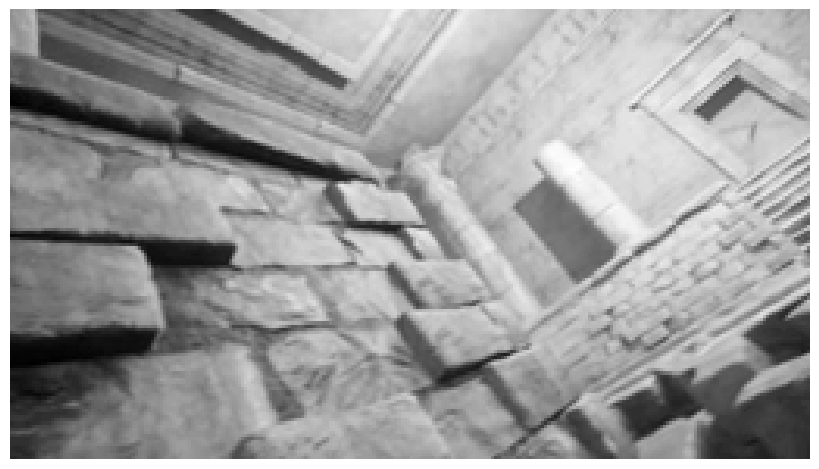

Stimulus: Rendered
Frame shape: (144, 256)


In [25]:
import h5py
import matplotlib.pyplot as plt

MICRONS_H5_PATH = "MICrONS\\microns.h5"

with h5py.File(MICRONS_H5_PATH, "r") as h5:

    selected_frame = None
    selected_name = None

    # Look for the first natural video
    for video_hash, video_group in h5["videos"].items():

        stimulus_type = video_group.attrs.get(
            "type",
            ""
        )

        # HDF5 attributes can sometimes be stored as bytes
        if isinstance(stimulus_type, bytes):
            stimulus_type = stimulus_type.decode()

        if stimulus_type == "Clip":

            clip = video_group["clip"]

            # Select a frame from the middle of the video
            frame_index = len(clip) // 3
            selected_frame = clip[frame_index]

            selected_name = video_group.attrs.get(
                "short_movie_name",
                video_hash
            )

            if isinstance(selected_name, bytes):
                selected_name = selected_name.decode()

            break


if selected_frame is None:
    raise RuntimeError("No natural Clip stimulus was found.")


plt.figure(figsize=(8, 6))

plt.imshow(
    selected_frame,
    cmap="gray"
)

plt.axis("off")
plt.tight_layout(pad=0)

plt.savefig(
    "microns_stimulus_example.png",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0
)

plt.show()

print("Stimulus:", selected_name)
print("Frame shape:", selected_frame.shape)

In [28]:
import os
import h5py
import imageio.v2 as imageio
import numpy as np


MICRONS_H5_PATH = "MICrONS\\microns.h5"
OUTPUT_DIR = "MICrONS\\stimulus_examples"

STIMULUS_TYPES = [
    "Clip",
    "Monet2",
    "Trippy",
]

# Use None to export the complete videos
MAX_SECONDS = 10

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)


with h5py.File(MICRONS_H5_PATH, "r") as h5:

    for stimulus_type in STIMULUS_TYPES:

        type_group = h5["types"][stimulus_type]

        # Select the first available stimulus of this type
        stimulus_hash = next(
            iter(type_group.keys())
        )

        # This is a SoftLink pointing toward /videos/<hash>
        video_group = type_group[stimulus_hash]

        clip = video_group["clip"]
        times = video_group["times"][:]

        # Calculate the actual frame rate from the timestamps
        if len(times) > 1:
            fps = float(
                1.0 / np.median(np.diff(times))
            )
        else:
            fps = 7.5

        n_frames = len(clip)

        if MAX_SECONDS is not None:
            n_frames = min(
                n_frames,
                int(MAX_SECONDS * fps)
            )

        output_path = os.path.join(
            OUTPUT_DIR,
            f"microns_{stimulus_type}_example.mp4"
        )

        print(
            f"Exporting {stimulus_type}: "
            f"{n_frames} frames at {fps:.2f} fps"
        )

        with imageio.get_writer(
            output_path,
            fps=fps,
            codec="libx264",
            quality=8,
            pixelformat="yuv420p",
        ) as writer:

            for frame_index in range(n_frames):

                frame = clip[frame_index]

                # Convert the grayscale image to RGB for PowerPoint
                frame_rgb = np.repeat(
                    frame[..., None],
                    3,
                    axis=2
                )

                writer.append_data(
                    frame_rgb
                )

        print("Saved:", output_path)

Exporting Clip: 75 frames at 7.50 fps


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (216, 126) to (224, 128) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).
IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=16, resizing from (160, 90) to (160, 96) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


Saved: MICrONS\stimulus_examples\microns_Clip_example.mp4
Exporting Monet2: 75 frames at 7.50 fps
Saved: MICrONS\stimulus_examples\microns_Monet2_example.mp4
Exporting Trippy: 75 frames at 7.50 fps
Saved: MICrONS\stimulus_examples\microns_Trippy_example.mp4


In [22]:
# =========================
# Load best model for a given dimension
# =========================

import os
import torch
import numpy as np
import pandas as pd

DIM_TO_ANALYZE = 1
ckpt_path = os.path.join(
    CHECKPOINT_DIR,
    f"best_dim_{DIM_TO_ANALYZE}.pt"
)

# Recreate model
model = VisibilityAwareEmbeddingModel(
    n_neurons=n_neurons,
    dim=DIM_TO_ANALYZE,
    positions=positions,
    positions_um=positions_um,
    distance_mean=distance_mean,
    distance_std=distance_std,
    axon_features=axon_features,
    dendrite_features=dendrite_features,
    axon_fully_proofread=axon_fully_proofread,
    dendrite_fully_proofread=dendrite_fully_proofread,
).to(DEVICE)

# Load checkpoint
ckpt = torch.load(
    ckpt_path,
    map_location=DEVICE,
    weights_only=False
)

model.load_state_dict(ckpt["model_state_dict"])
model.eval()

print(f"Loaded model for dim={DIM_TO_ANALYZE}")
print(f"Best epoch: {ckpt['best_epoch']}")
print(f"Best val loss: {ckpt['best_val_loss']:.4f}")


# =========================
# Extract latent vectors Z
# =========================

with torch.no_grad():
    Z = model.Z.weight.detach().cpu().numpy()

print("Z shape:", Z.shape)   # (n_neurons, DIM_TO_ANALYZE)



# =========================
# Convert to DataFrame
# =========================

df_Z = pd.DataFrame(
    Z,
    columns=[f"z{k+1}" for k in range(DIM_TO_ANALYZE)]
)

df_Z["neuron_idx"] = np.arange(len(df_Z))

# Optional: map back to pt_root_id
# all_ids is the ordered list used when creating id_map
# all_ids[i] corresponds to row i in Z

df_Z["pt_root_id"] = np.array(all_ids)

# ============================================================
# Remove duplicates
# ============================================================

units_unique = (
    units_cleaned
    .drop_duplicates(
        subset="pt_root_id",
        keep="first"
    )
    .copy()
)

print(
    "Duplicates in units_unique:",
    units_unique["pt_root_id"].duplicated().sum()
)


# ============================================================
# Build df_Z_full
# ============================================================

df_Z_full = df_Z.merge(
    units_unique,
    on="pt_root_id",
    how="left"
)
print(df_Z_full.head())

Loaded model for dim=1
Best epoch: 96
Best val loss: 0.0422
Z shape: (3398, 1)


NameError: name 'all_ids' is not defined

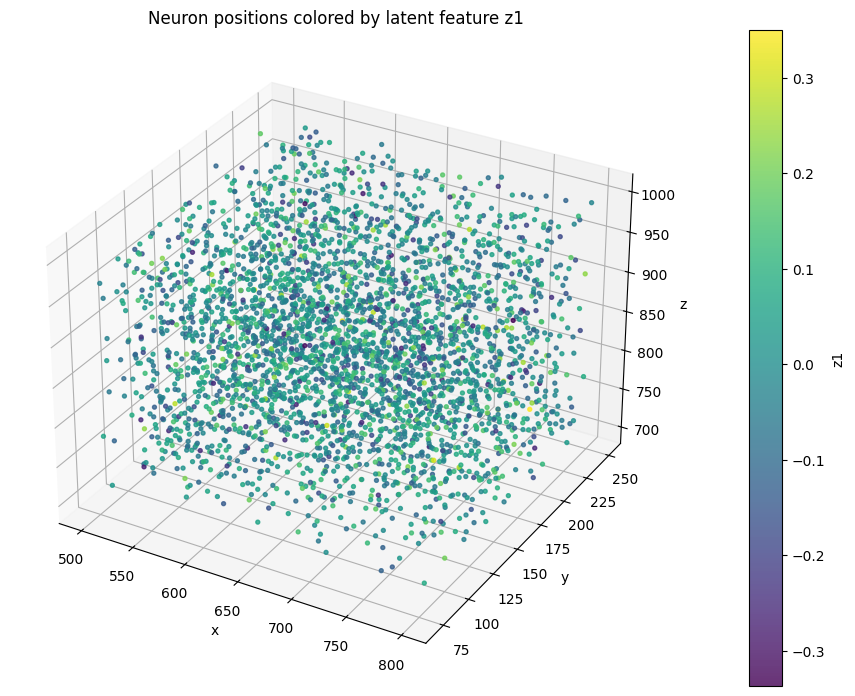

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

df_plot = df_Z_full.dropna(
    subset=["pt_position_x", "pt_position_y", "pt_position_z", "z1"]
).copy()

fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

sc = ax.scatter(
    df_plot["pt_position_x"],
    df_plot["pt_position_y"],
    df_plot["pt_position_z"],
    c=df_plot["z1"],
    s=8,
    alpha=0.8,
    cmap="viridis"
)

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Neuron positions colored by latent feature z1")

cbar = plt.colorbar(sc, ax=ax, pad=0.1)
cbar.set_label("z1")

plt.tight_layout()
plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_65344\4194641631.py:24: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


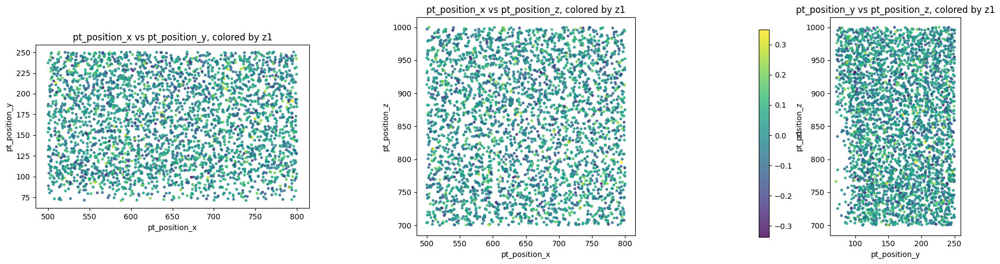

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

pairs = [
    ("pt_position_x", "pt_position_y"),
    ("pt_position_x", "pt_position_z"),
    ("pt_position_y", "pt_position_z"),
]

for ax, (a, b) in zip(axes, pairs):
    sc = ax.scatter(
        df_plot[a],
        df_plot[b],
        c=df_plot["z1"],
        s=8,
        alpha=0.8,
        cmap="viridis"
    )
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.set_title(f"{a} vs {b}, colored by z1")
    ax.set_aspect("equal", adjustable="box")

plt.colorbar(sc, ax=axes, label="z1")
plt.tight_layout()
plt.show()

In [ ]:
from scipy.stats import spearmanr
import pandas as pd
import numpy as np


# ============================================================
# Data
# ============================================================

df_Z_full = df_Z_full.merge(readout_unique[ 
    ["pt_root_id", 
     "readout_weight", 
     "readout_mu_x", 
     "readout_mu_y", 
     "session", 
     "scan_idx", 
     "unit_id", 
     "residual", 
     "score" ] ], 
     on="pt_root_id", how="left" )

print(df_Z_full)


df_Z_readout = df_Z_full[
    df_Z_full["readout_weight"].notna()
].copy().reset_index(drop=True)
latent_cols = [c for c in df_Z_readout.columns if c.startswith("z")]

R = np.stack(df_Z_readout["readout_weight"].values)

print("R shape:", R.shape)

threshold = 0.30

results = []

# ============================================================
# Correlations
# ============================================================

for z in latent_cols:

    z_values = df_Z_readout[z].values

    for j in range(512):

        rho, pval = spearmanr(
            z_values,
            R[:, j]
        )

        if np.abs(rho) >= threshold:

            results.append({
                "latent": z,
                "readout_dim": j,
                "rho": rho,
                "abs_rho": abs(rho),
                "pvalue": pval,
            })

corr_df = pd.DataFrame(results)

"""corr_df = corr_df.sort_values(
    "abs_rho",
    ascending=False
)"""

print(corr_df)

            z1  neuron_idx          pt_root_id  pt_position_x  pt_position_y  \
0    -0.023576           0  864691134885142778     596.029358     126.515236   
1    -0.122528           1  864691134885735418     788.885071     105.290947   
2     0.097615           2  864691134886095610     616.010559     190.387756   
3     0.062905           3  864691134917923338     544.262146     179.228012   
4    -0.027982           4  864691134918694410     629.363098     150.118271   
...        ...         ...                 ...            ...            ...   
3393  0.026590        3393  864691135911082153     759.395264      99.434456   
3394 -0.185831        3394  864691135741004651     505.842499     243.130692   
3395  0.068967        3395  864691135429769520     766.894714     250.165649   
3396  0.088810        3396  864691136057171416     783.436584     128.648972   
3397  0.120506        3397  864691136371310728     756.323120     247.634644   

      pt_position_z classification_syst

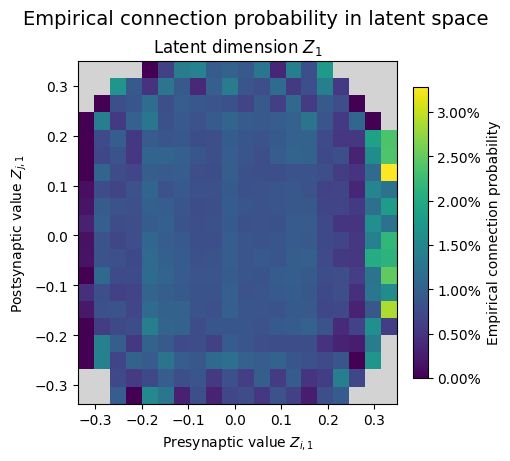

In [ ]:
# ============================================================
# Empirical P(connection) as a function of Z_pre and Z_post
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


N_BINS = 20
MIN_PAIRS_PER_CELL = 100


# Existing tensors -> NumPy
pre_np = pre_idx.detach().cpu().numpy()
post_np = post_idx.detach().cpu().numpy()
y_np = y.detach().cpu().numpy()


heatmaps = []
edges_by_dim = []


# ============================================================
# Compute empirical probabilities
# ============================================================

for k in range(DIM_TO_ANALYZE):

    z_pre = Z[pre_np, k]
    z_post = Z[post_np, k]

    z_edges = np.linspace(
        min(z_pre.min(), z_post.min()),
        max(z_pre.max(), z_post.max()),
        N_BINS + 1,
    )

    # Number of possible connections in each cell
    n_possible, _, _ = np.histogram2d(
        z_pre,
        z_post,
        bins=[z_edges, z_edges],
    )

    # Number of observed connections in each cell
    n_connections, _, _ = np.histogram2d(
        z_pre,
        z_post,
        bins=[z_edges, z_edges],
        weights=y_np,
    )

    # P(connection) = observed / possible
    empirical_probability = np.divide(
        n_connections,
        n_possible,
        out=np.full_like(
            n_connections,
            np.nan,
            dtype=float,
        ),
        where=n_possible > 0,
    )

    empirical_probability[
        n_possible < MIN_PAIRS_PER_CELL
    ] = np.nan

    heatmaps.append(empirical_probability)
    edges_by_dim.append(z_edges)


# Common color scale
vmax = np.nanmax([
    np.nanmax(heatmap)
    for heatmap in heatmaps
])


# ============================================================
# Plot
# ============================================================

fig, axes = plt.subplots(
    1,
    DIM_TO_ANALYZE,
    figsize=(5 * DIM_TO_ANALYZE, 4.5),
    squeeze=False,
    constrained_layout=True,
)

axes = axes.ravel()

cmap = plt.cm.viridis.copy()
cmap.set_bad("lightgrey")


for k, ax in enumerate(axes):

    z_edges = edges_by_dim[k]

    im = ax.pcolormesh(
        z_edges,
        z_edges,
        heatmaps[k].T,
        shading="auto",
        cmap=cmap,
        vmin=0,
        vmax=vmax,
    )

    ax.set_title(
        rf"Latent dimension $Z_{k+1}$"
    )

    ax.set_xlabel(
        rf"Presynaptic value $Z_{{i,{k+1}}}$"
    )

    ax.set_ylabel(
        rf"Postsynaptic value $Z_{{j,{k+1}}}$"
    )


colorbar = fig.colorbar(
    im,
    ax=axes.tolist(),
    shrink=0.85,
)

colorbar.set_label(
    "Empirical connection probability"
)

colorbar.ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=1)
)

fig.suptitle(
    "Empirical connection probability in latent space",
    fontsize=14,
)

plt.savefig(
    "empirical_connection_probability_latent_heatmaps.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, pearsonr
from sklearn.decomposition import PCA


# ============================================================
# 1. Select latent and biological columns
# ============================================================

latent_cols = [
    c for c in df_Z_full.columns
    if c.startswith("z")
]

candidate_bio_cols = [
    "pt_position_x",
    "pt_position_y",
    "pt_position_z",
    "pref_ori_fit",
    "pref_dir_fit",
    "g_osi_dg",
    "g_dsi_dg",
    "firing_rate",
    "readout_mu_x",
    "readout_mu_y"
]

bio_cols = [
    c for c in candidate_bio_cols
    if c in df_Z_full.columns
]

print("Latent columns:", latent_cols)
print("Biological columns:", bio_cols)

Latent columns: ['z1']
Biological columns: ['pt_position_x', 'pt_position_y', 'pt_position_z', 'pref_ori_fit', 'readout_mu_x', 'readout_mu_y']


In [ ]:
# ============================================================
# 2. Correlation matrix
# ============================================================

corr_spearman = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

corr_pearson = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

pval_spearman = pd.DataFrame(
    index=latent_cols,
    columns=bio_cols,
    dtype=float
)

for z in latent_cols:
    for b in bio_cols:

        tmp = df_Z_full[[z, b]].dropna()

        if len(tmp) < 5:
            corr_spearman.loc[z, b] = np.nan
            corr_pearson.loc[z, b] = np.nan
            pval_spearman.loc[z, b] = np.nan
            continue

        rho, pval = spearmanr(
            tmp[z],
            tmp[b]
        )

        r, _ = pearsonr(
            tmp[z],
            tmp[b]
        )

        corr_spearman.loc[z, b] = rho
        corr_pearson.loc[z, b] = r
        pval_spearman.loc[z, b] = pval

print("=== Spearman correlation ===")
print(corr_spearman)

print("\n=== Pearson correlation ===")
print(corr_pearson)

=== Spearman correlation ===
    pt_position_x  pt_position_y  pt_position_z  pref_ori_fit  readout_mu_x  \
z1       0.011491      -0.024991      -0.014192     -0.033769     -0.007709   

    readout_mu_y  
z1     -0.008895  

=== Pearson correlation ===
    pt_position_x  pt_position_y  pt_position_z  pref_ori_fit  readout_mu_x  \
z1       0.015842      -0.021305      -0.015244     -0.026956     -0.007962   

    readout_mu_y  
z1     -0.006652  


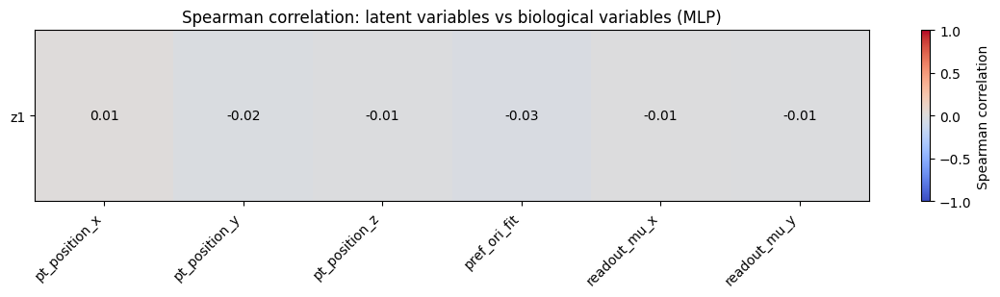

In [ ]:
# ============================================================
# 3. Heatmap Spearman correlations
# ============================================================

plt.figure(figsize=(1.4 * len(bio_cols) + 3, 1.2 * len(latent_cols) + 2))

plt.imshow(
    corr_spearman.astype(float),
    aspect="auto",
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

plt.colorbar(
    label="Spearman correlation"
)

plt.xticks(
    ticks=np.arange(len(bio_cols)),
    labels=bio_cols,
    rotation=45,
    ha="right"
)

plt.yticks(
    ticks=np.arange(len(latent_cols)),
    labels=latent_cols
)

for i, z in enumerate(latent_cols):
    for j, b in enumerate(bio_cols):
        val = corr_spearman.loc[z, b]

        if not np.isnan(val):
            plt.text(
                j,
                i,
                f"{val:.2f}",
                ha="center",
                va="center",
                color="black"
            )

plt.title("Spearman correlation: latent variables vs biological variables (MLP)")
plt.tight_layout()
plt.show()

=== Strongest correlations ===
z1  pref_ori_fit     0.033769
    pt_position_y    0.024991
    pt_position_z    0.014192
    pt_position_x    0.011491
    readout_mu_y     0.008895
    readout_mu_x     0.007709
dtype: float64


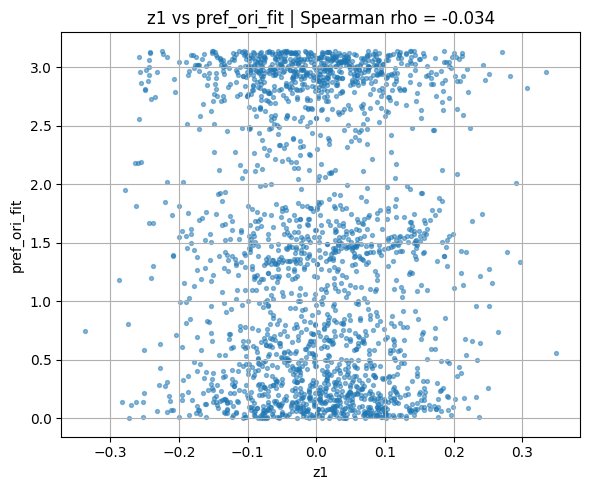

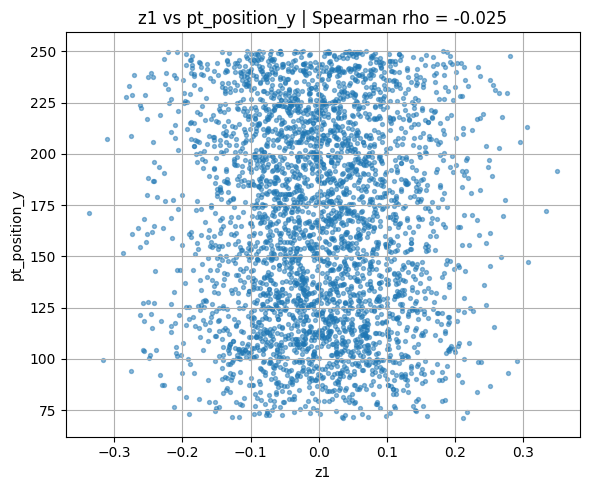

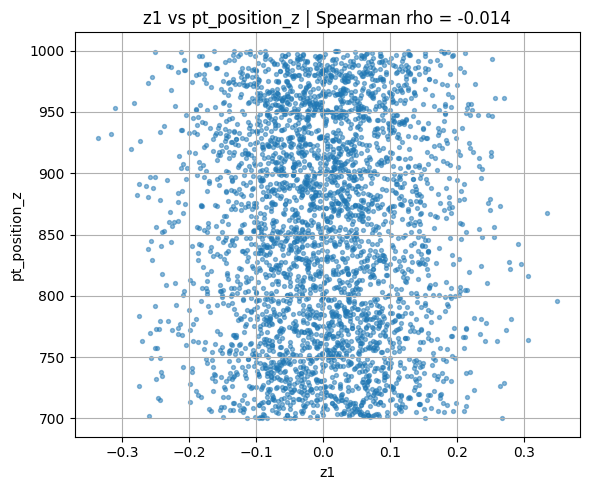

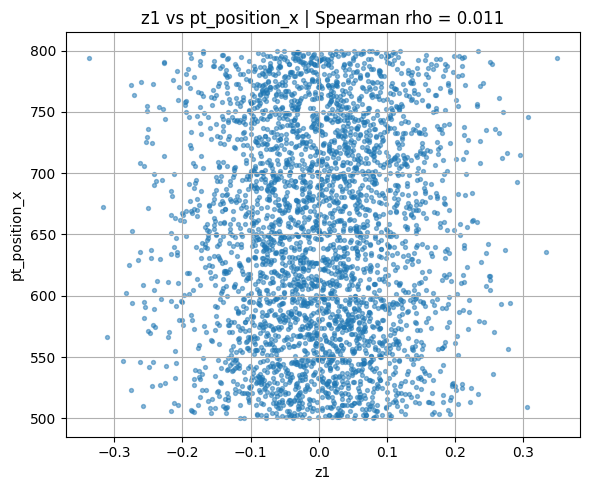

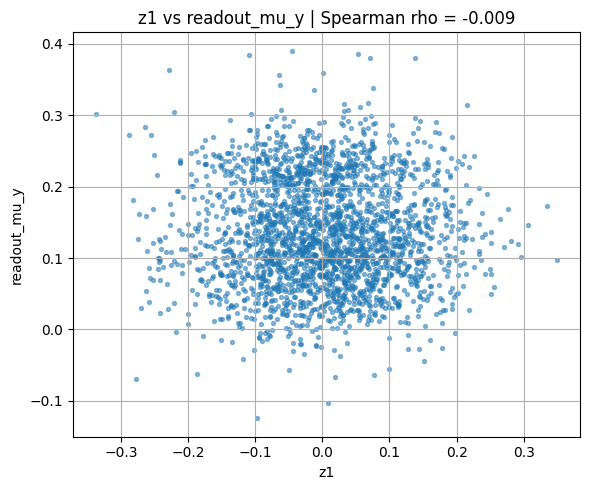

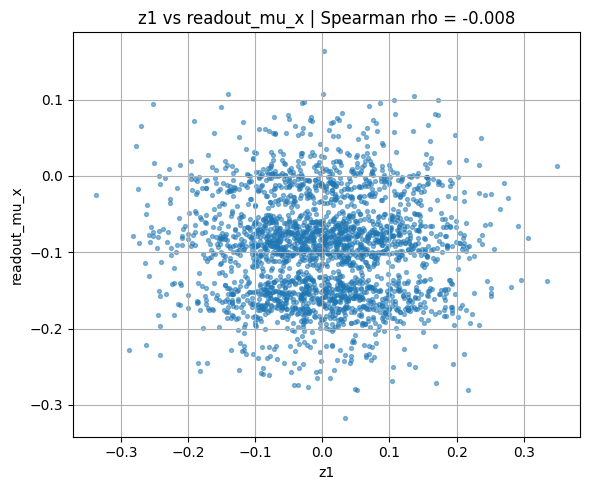

In [ ]:
# ============================================================
# 4. Scatter plots for strongest correlations
# ============================================================

corr_abs = (
    corr_spearman
    .abs()
    .stack()
    .sort_values(ascending=False)
)

top_pairs = corr_abs.head(6)

print("=== Strongest correlations ===")
print(top_pairs)

for (z, b), _ in top_pairs.items():

    tmp = df_Z_full[[z, b]].dropna()

    plt.figure(figsize=(6, 5))

    plt.scatter(
        tmp[z],
        tmp[b],
        s=8,
        alpha=0.5
    )

    rho = corr_spearman.loc[z, b]

    plt.xlabel(z)
    plt.ylabel(b)
    plt.title(
        f"{z} vs {b} | Spearman rho = {rho:.3f}"
    )

    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# 5. PCA of latent embedding
# ============================================================

Z_cols = df_Z_full[latent_cols].dropna()

if len(latent_cols) >= 2:

    pca = PCA(n_components=2)

    Z_pca = pca.fit_transform(
        Z_cols.values
    )

    df_pca = df_Z_full.loc[
        Z_cols.index
    ].copy()

    df_pca["PC1"] = Z_pca[:, 0]
    df_pca["PC2"] = Z_pca[:, 1]

    print(
        "PCA explained variance:",
        pca.explained_variance_ratio_
    )

    color_cols = [
        c for c in [
            "pt_position_x",
            "pt_position_y",
            "pt_position_z",
            "pref_ori_fit",
            "g_osi_dg",
            "g_dsi_dg",
            "readout_mu_x",
            "readout_mu_y"
        ]
        if c in df_pca.columns
    ]

    for c in color_cols:

        tmp = df_pca[["PC1", "PC2", c]].dropna()

        plt.figure(figsize=(7, 6))

        sc = plt.scatter(
            tmp["PC1"],
            tmp["PC2"],
            c=tmp[c],
            s=8,
            alpha=0.8,
            cmap="viridis"
        )

        plt.xlabel("PC1")
        plt.ylabel("PC2")

        plt.title(
            f"PCA of latent space colored by {c} (MLP)"
        )

        plt.colorbar(sc, label=c)
        plt.axis("equal")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

else:
    print("PCA skipped: latent dimension < 2")

PCA skipped: latent dimension < 2


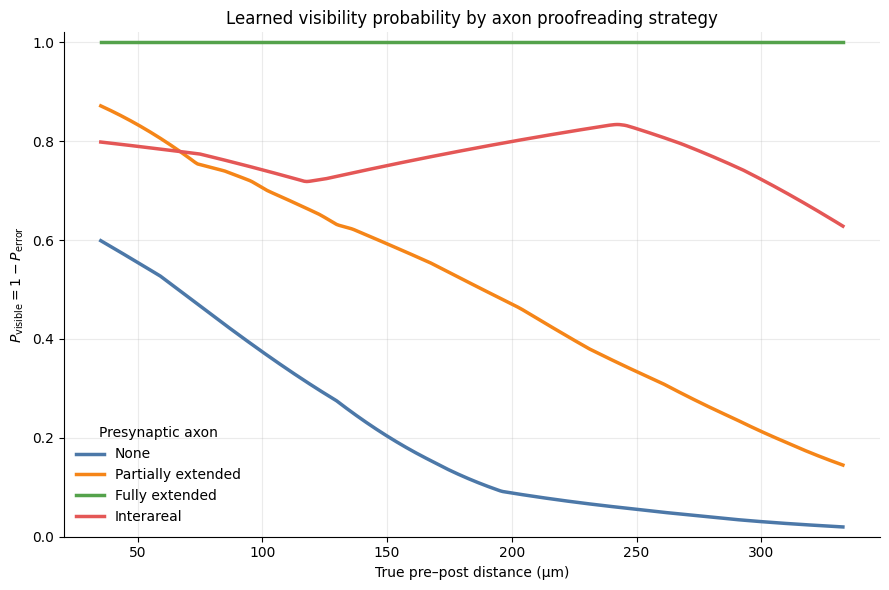

In [ ]:
# ============================================================
# Learned P(visible) = 1 - P(error)
# for each axon proofreading strategy
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import torch


model.eval()

expected_error_input = (
    1
    + len(AXON_CATEGORIES)
)

assert model.error_mlp[0].in_features == expected_error_input, (
    f"error_mlp expects {model.error_mlp[0].in_features} inputs, "
    f"but {expected_error_input} are required."
)


# ============================================================
# True distance range observed in the test set
# ============================================================

test_indices = torch.as_tensor(
    np.asarray(test_set.indices),
    dtype=torch.long,
    device=DEVICE,
)

pre_test = pre_idx[test_indices]
post_test = post_idx[test_indices]


with torch.no_grad():

    observed_distances_um = torch.linalg.vector_norm(
        model.positions_um[pre_test]
        - model.positions_um[post_test],
        dim=1,
    )

    # Remove extreme outliers for a clearer graph

    min_distance_um = torch.quantile(
        observed_distances_um,
        0.01,
    ).item()

    max_distance_um = torch.quantile(
        observed_distances_um,
        0.99,
    ).item()


# Grid displayed in real µm

distance_grid_um = torch.linspace(
    min_distance_um,
    max_distance_um,
    300,
    device=DEVICE,
)

# Same distances normalized exactly as during training

distance_grid_normalized = (
    distance_grid_um
    - model.distance_mean
) / model.distance_std


# ============================================================
# Evaluate each axon proofreading strategy
# ============================================================

visibility_curves = {}


with torch.no_grad():

    for axon_index, axon_name in enumerate(
        AXON_CATEGORIES
    ):

        axon_one_hot = torch.zeros(
            len(distance_grid_um),
            len(AXON_CATEGORIES),
            device=DEVICE,
        )

        axon_one_hot[
            :,
            axon_index
        ] = 1.0

        error_input = torch.cat(
            [
                distance_grid_normalized.unsqueeze(1),
                axon_one_hot,
            ],
            dim=1,
        )

        error_logits = (
            model.error_mlp(
                error_input
            )
            .squeeze(1)
        )

        p_error = torch.sigmoid(
            error_logits
        )

        # Hard constraint:
        # fully extended axon => P(error) = 0

        if axon_name == "axon_fully_extended":

            p_visible = torch.ones_like(
                p_error
            )

        else:

            p_visible = (
                1.0 - p_error
            )

        visibility_curves[
            axon_name
        ] = (
            p_visible
            .cpu()
            .numpy()
        )


distance_grid_um_np = (
    distance_grid_um
    .cpu()
    .numpy()
)


# ============================================================
# Plot
# ============================================================

colors = {
    "none": "#4C78A8",
    "axon_partially_extended": "#F58518",
    "axon_fully_extended": "#54A24B",
    "axon_interareal": "#E45756",
}

labels = {
    "none": "None",
    "axon_partially_extended": "Partially extended",
    "axon_fully_extended": "Fully extended",
    "axon_interareal": "Interareal",
}


fig, ax = plt.subplots(
    figsize=(9, 6)
)


for axon_name in AXON_CATEGORIES:

    ax.plot(
        distance_grid_um_np,
        visibility_curves[axon_name],
        linewidth=2.5,
        color=colors[axon_name],
        label=labels[axon_name],
    )


ax.set_xlabel(
    "True pre–post distance (µm)"
)

ax.set_ylabel(
    r"$P_{\mathrm{visible}} = 1-P_{\mathrm{error}}$"
)

ax.set_ylim(
    0,
    1.02
)

ax.set_title(
    "Learned visibility probability by axon proofreading strategy"
)

ax.legend(
    title="Presynaptic axon",
    frameon=False,
)

ax.grid(
    alpha=0.25
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig(
    "visibility_vs_distance_by_axon_proofreading.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()

In [ ]:
# ============================================================
# 5. PCA of latent embedding
# ============================================================

Z_cols = df_Z_full[latent_cols].dropna()

if len(latent_cols) >= 2:

    pca = PCA(n_components=2)

    Z_pca = pca.fit_transform(
        Z_cols.values
    )

    df_pca = df_Z_full.loc[
        Z_cols.index
    ].copy()

    df_pca["PC1"] = Z_pca[:, 0]
    df_pca["PC2"] = Z_pca[:, 1]

    print(
        "PCA explained variance:",
        pca.explained_variance_ratio_
    )

    color_cols = [
        c for c in [
            "pt_position_x",
            "pt_position_y",
            "pt_position_z",
            "pref_ori_fit",
            "g_osi_dg",
            "g_dsi_dg",
            "readout_mu_x",
            "readout_mu_y"
        ]
        if c in df_pca.columns
    ]

    for c in color_cols:

        tmp = df_pca[["PC1", "PC2", c]].dropna()

        plt.figure(figsize=(7, 6))

        sc = plt.scatter(
            tmp["PC1"],
            tmp["PC2"],
            c=tmp[c],
            s=8,
            alpha=0.8,
            cmap="viridis"
        )

        plt.xlabel("PC1")
        plt.ylabel("PC2")

        plt.title(
            f"PCA of latent space colored by {c} (MLP)"
        )

        plt.colorbar(sc, label=c)
        plt.axis("equal")
        plt.grid(True)
        plt.tight_layout()
        plt.show()

else:
    print("PCA skipped: latent dimension < 2")

PCA skipped: latent dimension < 2


Number of neurons: 2375
Readout shape: (2375, 512)
Latent shape: (2375, 1)

Best linear parameters:
{'regressor__ridge__alpha': np.float64(1000.0)}

Best MLP parameters:
{'regressor__mlp__alpha': 0.001, 'regressor__mlp__hidden_layer_sizes': (32,)}

Whole-vector test metrics:


,test_R2,explained_variance,mean_euclidean,median_euclidean,pearson_r
model,,,,,
Linear,-0.0453,-0.0424,0.7744,0.6351,0.0710
Linear shuffled,-0.0712,-0.0671,0.7862,0.6840,0.0326
MLP,-0.3629,-0.3591,0.9023,0.8058,0.0633
MLP shuffled,-0.4164,-0.4153,0.9264,0.8070,0.0111



Test R2 for each latent dimension:


,latent_dimension,Linear,Linear shuffled,MLP,MLP shuffled
0,z1,-0.0453,-0.0712,-0.3629,-0.4164



Note: cosine similarity is not informative for a one-dimensional latent space. Pearson correlation is reported instead.


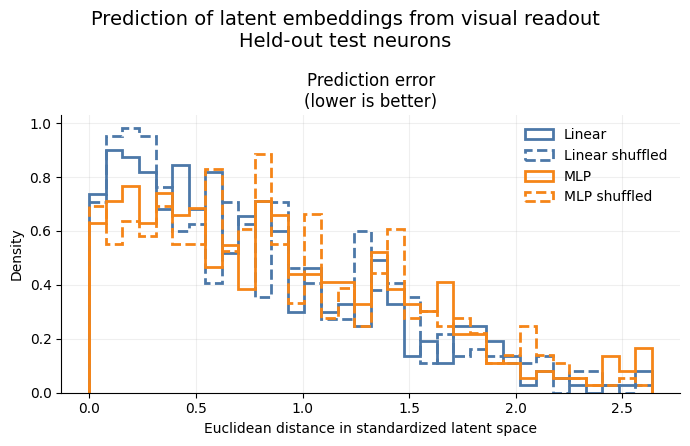

In [ ]:
# ============================================================
# How much of the latent vector Z is explained by visual readout?
#
# Models:
#   1. Linear Ridge regression
#   2. Nonlinear MLP
#   3. Ridge trained with shuffled readout/Z pairing
#   4. MLP trained with shuffled readout/Z pairing
#
# Evaluation:
#   - Hyperparameters selected by cross-validation on training neurons
#   - Final metrics calculated only on held-out test neurons
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    r2_score,
    explained_variance_score,
)
from sklearn.model_selection import (
    train_test_split,
    KFold,
    GridSearchCV,
)
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# ============================================================
# Parameters
# ============================================================

SEED = 42
TEST_SIZE = 0.20
CV_FOLDS = 5
N_JOBS = -1


# ============================================================
# Data
#
# R: visual readout vectors
# Z: complete latent embedding vectors
# ============================================================

latent_cols = sorted(
    [c for c in df_Z_readout.columns if c.startswith("z")],
    key=lambda c: int(c[1:]),
)

R = np.stack(
    df_Z_readout["readout_weight"].to_numpy()
).astype(np.float32)

Z_observed = df_Z_readout[
    latent_cols
].to_numpy(dtype=np.float32)


# Remove neurons containing invalid values
valid_rows = (
    np.isfinite(R).all(axis=1)
    & np.isfinite(Z_observed).all(axis=1)
)

R = R[valid_rows]
Z_observed = Z_observed[valid_rows]

n_neurons_analysis = len(R)
n_latent = Z_observed.shape[1]

print("Number of neurons:", n_neurons_analysis)
print("Readout shape:", R.shape)
print("Latent shape:", Z_observed.shape)


# ============================================================
# Train/test split by neuron
# ============================================================

all_indices = np.arange(n_neurons_analysis)

train_indices, test_indices = train_test_split(
    all_indices,
    test_size=TEST_SIZE,
    random_state=SEED,
)

R_train = R[train_indices]
R_test = R[test_indices]

Z_train = Z_observed[train_indices]
Z_test = Z_observed[test_indices]


# sklearn prefers a 1D target when there is only one output
def target_for_sklearn(Z):
    if Z.shape[1] == 1:
        return Z.ravel()
    return Z


def prediction_to_2d(prediction):
    prediction = np.asarray(prediction)

    if prediction.ndim == 1:
        prediction = prediction[:, None]

    return prediction


Z_train_fit = target_for_sklearn(Z_train)


# ============================================================
# Inner cross-validation
# ============================================================

inner_cv = KFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=SEED,
)


# ============================================================
# 1. Linear model: Ridge regression
#
# X and Z are standardized inside each CV fold.
# ============================================================

linear_model = TransformedTargetRegressor(
    regressor=Pipeline([
        (
            "readout_scaler",
            StandardScaler(),
        ),
        (
            "ridge",
            Ridge(),
        ),
    ]),
    transformer=StandardScaler(),
)

linear_search = GridSearchCV(
    estimator=linear_model,
    param_grid={
        "regressor__ridge__alpha": np.logspace(
            -3,
            3,
            7,
        )
    },
    scoring="neg_mean_squared_error",
    cv=inner_cv,
    n_jobs=N_JOBS,
)

linear_search.fit(
    R_train,
    Z_train_fit,
)

Z_pred_linear = prediction_to_2d(
    linear_search.predict(R_test)
)


# ============================================================
# 2. Nonlinear model: MLP
# ============================================================

mlp_model = TransformedTargetRegressor(
    regressor=Pipeline([
        (
            "readout_scaler",
            StandardScaler(),
        ),
        (
            "mlp",
            MLPRegressor(
                activation="relu",
                solver="adam",
                batch_size=64,
                max_iter=1000,
                early_stopping=True,
                validation_fraction=0.15,
                n_iter_no_change=20,
                random_state=SEED,
            ),
        ),
    ]),
    transformer=StandardScaler(),
)

mlp_search = GridSearchCV(
    estimator=mlp_model,
    param_grid={
        "regressor__mlp__hidden_layer_sizes": [
            (32,),
            (64,),
        ],
        "regressor__mlp__alpha": [
            1e-4,
            1e-3,
        ],
    },
    scoring="neg_mean_squared_error",
    cv=inner_cv,
    n_jobs=N_JOBS,
)

mlp_search.fit(
    R_train,
    Z_train_fit,
)

Z_pred_mlp = prediction_to_2d(
    mlp_search.predict(R_test)
)


# ============================================================
# Shuffled control
#
# Only the training correspondence between R and Z is shuffled.
# The test set remains unchanged.
#
# The shuffled models use the hyperparameters selected above,
# ensuring the same model complexity.
# ============================================================

rng = np.random.default_rng(SEED)

shuffle_order = rng.permutation(
    len(Z_train)
)

Z_train_shuffled = Z_train[
    shuffle_order
]

Z_train_shuffled_fit = target_for_sklearn(
    Z_train_shuffled
)


linear_shuffled_model = clone(
    linear_search.best_estimator_
)

linear_shuffled_model.fit(
    R_train,
    Z_train_shuffled_fit,
)

Z_pred_linear_shuffled = prediction_to_2d(
    linear_shuffled_model.predict(R_test)
)


mlp_shuffled_model = clone(
    mlp_search.best_estimator_
)

mlp_shuffled_model.fit(
    R_train,
    Z_train_shuffled_fit,
)

Z_pred_mlp_shuffled = prediction_to_2d(
    mlp_shuffled_model.predict(R_test)
)


# ============================================================
# Standardize the latent space using training statistics
#
# This prevents one latent dimension from dominating Euclidean
# distance simply because it has a larger numerical scale.
# ============================================================

Z_mean = Z_train.mean(
    axis=0,
    keepdims=True,
)

Z_std = Z_train.std(
    axis=0,
    keepdims=True,
)

Z_std = np.where(
    Z_std < 1e-8,
    1.0,
    Z_std,
)


def standardize_Z(Z):
    return (Z - Z_mean) / Z_std


Z_test_scaled = standardize_Z(
    Z_test
)

predictions_scaled = {
    "Linear": standardize_Z(
        Z_pred_linear
    ),
    "Linear shuffled": standardize_Z(
        Z_pred_linear_shuffled
    ),
    "MLP": standardize_Z(
        Z_pred_mlp
    ),
    "MLP shuffled": standardize_Z(
        Z_pred_mlp_shuffled
    ),
}


# ============================================================
# Vector metrics for each test neuron
# ============================================================

def cosine_by_neuron(Z_true, Z_pred):

    numerator = np.sum(
        Z_true * Z_pred,
        axis=1,
    )

    denominator = (
        np.linalg.norm(Z_true, axis=1)
        * np.linalg.norm(Z_pred, axis=1)
    )

    cosine = np.divide(
        numerator,
        denominator,
        out=np.full_like(
            numerator,
            np.nan,
            dtype=float,
        ),
        where=denominator > 1e-12,
    )

    return cosine


def euclidean_by_neuron(Z_true, Z_pred):

    return np.linalg.norm(
        Z_true - Z_pred,
        axis=1,
    )


vector_distributions = {}
metric_rows = []

for model_name, Z_prediction in predictions_scaled.items():

    euclidean_values = euclidean_by_neuron(
        Z_test_scaled,
        Z_prediction,
    )

    if n_latent >= 2:
        cosine_values = cosine_by_neuron(
            Z_test_scaled,
            Z_prediction,
        )
    else:
        # In one dimension, cosine is essentially only a sign test
        cosine_values = np.full(
            len(Z_test_scaled),
            np.nan,
        )

    vector_distributions[model_name] = {
        "cosine": cosine_values,
        "euclidean": euclidean_values,
    }

    row = {
        "model": model_name,

        "test_R2": r2_score(
            Z_test_scaled,
            Z_prediction,
            multioutput="uniform_average",
        ),

        "explained_variance": explained_variance_score(
            Z_test_scaled,
            Z_prediction,
            multioutput="uniform_average",
        ),

        "mean_euclidean": np.mean(
            euclidean_values
        ),

        "median_euclidean": np.median(
            euclidean_values
        ),
    }

    if n_latent >= 2:

        row["mean_cosine"] = np.nanmean(
            cosine_values
        )

        row["median_cosine"] = np.nanmedian(
            cosine_values
        )

    else:

        row["pearson_r"] = np.corrcoef(
            Z_test_scaled[:, 0],
            Z_prediction[:, 0],
        )[0, 1]

    metric_rows.append(row)


metrics_df = (
    pd.DataFrame(metric_rows)
    .set_index("model")
)


# ============================================================
# R2 for each individual latent dimension
# ============================================================

per_dimension_results = pd.DataFrame({
    model_name: r2_score(
        Z_test_scaled,
        Z_prediction,
        multioutput="raw_values",
    )
    for model_name, Z_prediction
    in predictions_scaled.items()
})

per_dimension_results.insert(
    0,
    "latent_dimension",
    latent_cols,
)


# ============================================================
# Results
# ============================================================

print("\nBest linear parameters:")
print(linear_search.best_params_)

print("\nBest MLP parameters:")
print(mlp_search.best_params_)

print("\nWhole-vector test metrics:")
display(metrics_df.round(4))

print("\nTest R2 for each latent dimension:")
display(per_dimension_results.round(4))

if n_latent == 1:
    print(
        "\nNote: cosine similarity is not informative for a "
        "one-dimensional latent space. Pearson correlation is "
        "reported instead."
    )


# ============================================================
# Plot distributions on held-out test neurons
# ============================================================

styles = {
    "Linear": {
        "color": "#4C78A8",
        "linestyle": "-",
    },
    "Linear shuffled": {
        "color": "#4C78A8",
        "linestyle": "--",
    },
    "MLP": {
        "color": "#F58518",
        "linestyle": "-",
    },
    "MLP shuffled": {
        "color": "#F58518",
        "linestyle": "--",
    },
}


if n_latent >= 2:

    fig, axes = plt.subplots(
        1,
        2,
        figsize=(12, 4.5),
    )

    cosine_bins = np.linspace(
        -1,
        1,
        35,
    )

    for model_name, values in vector_distributions.items():

        axes[0].hist(
            values["cosine"],
            bins=cosine_bins,
            density=True,
            histtype="step",
            linewidth=2,
            color=styles[model_name]["color"],
            linestyle=styles[model_name]["linestyle"],
            label=model_name,
        )

    axes[0].set_xlabel(
        "Cosine similarity"
    )

    axes[0].set_ylabel(
        "Density"
    )

    axes[0].set_title(
        "Direction of the predicted latent vector\n(higher is better)"
    )


else:

    fig, ax = plt.subplots(
        1,
        1,
        figsize=(7, 4.5),
    )

    axes = [ax]


all_euclidean_values = np.concatenate([
    values["euclidean"]
    for values in vector_distributions.values()
])

euclidean_max = np.quantile(
    all_euclidean_values,
    0.99,
)

euclidean_bins = np.linspace(
    0,
    max(euclidean_max, 1e-8),
    35,
)

euclidean_axis = (
    axes[1]
    if n_latent >= 2
    else axes[0]
)

for model_name, values in vector_distributions.items():

    euclidean_axis.hist(
        values["euclidean"],
        bins=euclidean_bins,
        density=True,
        histtype="step",
        linewidth=2,
        color=styles[model_name]["color"],
        linestyle=styles[model_name]["linestyle"],
        label=model_name,
    )

euclidean_axis.set_xlabel(
    "Euclidean distance in standardized latent space"
)

euclidean_axis.set_ylabel(
    "Density"
)

euclidean_axis.set_title(
    "Prediction error\n(lower is better)"
)

euclidean_axis.legend(
    frameon=False
)


for ax in axes:

    ax.grid(
        alpha=0.20
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


fig.suptitle(
    "Prediction of latent embeddings from visual readout\n"
    "Held-out test neurons",
    fontsize=14,
)

plt.tight_layout()
plt.show()

In [ ]:
def explore_h5(g, prefix=""):
    for k in g.keys():
        item = g[k]
        path = f"{prefix}/{k}"
        print(path, type(item), getattr(item, "shape", ""))
        if isinstance(item, h5py.Group):
            explore_h5(item, path)

explore_h5(h5)

/brain_areas <class 'h5py._hl.group.Group'> 
/brain_areas/AL <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7 <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7/meta <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7/meta/area_indices <class 'h5py._hl.group.Group'> 
/brain_areas/AL/4_7/meta/area_indices/AL <class 'h5py._hl.dataset.Dataset'> (387,)
/brain_areas/AL/4_7/meta/area_indices/LM <class 'h5py._hl.dataset.Dataset'> (983,)
/brain_areas/AL/4_7/meta/area_indices/RL <class 'h5py._hl.dataset.Dataset'> (811,)
/brain_areas/AL/4_7/meta/area_indices/V1 <class 'h5py._hl.dataset.Dataset'> (5312,)
/brain_areas/AL/4_7/meta/brain_areas <class 'h5py._hl.dataset.Dataset'> (7493,)
/brain_areas/AL/4_7/meta/condition_hashes <class 'h5py._hl.dataset.Dataset'> (464,)
/brain_areas/AL/4_7/meta/coordinates <class 'h5py._hl.dataset.Dataset'> (7493, 3)
/brain_areas/AL/4_7/meta/unit_ids <class 'h5py._hl.dataset.Dataset'> (7493,)
/brain_areas/AL/4_7/trials <class 'h5py._hl.group.Group'> 
/brain_areas/

Z_valid shape: (2375, 1)
F shape: (2375, 512)
Spearman rho = 0.001, p = 6.65e-01


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_65344\1679691331.py:72: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  curve = res.groupby("bin").agg(


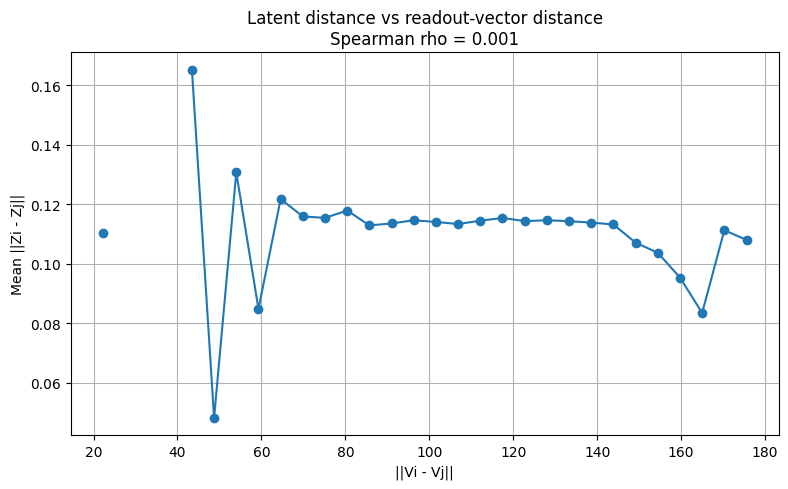

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

feature = "readout_weight"

# neurones valides
df = df_Z_full.dropna(subset=[feature]).copy()

idx = df["neuron_idx"].values

Z_valid = Z[idx]

# IMPORTANT : convertir la colonne de vecteurs en matrice
F = np.stack(
    df[feature].values
).astype(np.float32)

print("Z_valid shape:", Z_valid.shape)
print("F shape:", F.shape)

# -------------------------
# échantillonnage
# -------------------------

n_pairs = 200000
rng = np.random.default_rng(42)

i = rng.integers(0, len(df), n_pairs)
j = rng.integers(0, len(df), n_pairs)

mask = i != j
i = i[mask]
j = j[mask]

# -------------------------
# distances
# -------------------------

latent_dist = np.linalg.norm(
    Z_valid[i] - Z_valid[j],
    axis=1
)

feature_dist = np.linalg.norm(
    F[i] - F[j],
    axis=1
)

rho, pval = spearmanr(
    feature_dist,
    latent_dist
)

print(f"Spearman rho = {rho:.3f}, p = {pval:.2e}")

# -------------------------
# dataframe
# -------------------------

res = pd.DataFrame({
    "feature_dist": feature_dist,
    "latent_dist": latent_dist
})

res["bin"] = pd.cut(
    res["feature_dist"],
    bins=30
)

curve = res.groupby("bin").agg(
    mean_latent=("latent_dist", "mean"),
    n_pairs=("latent_dist", "size")
)

centers = np.array([
    b.mid for b in curve.index
])

# -------------------------
# plot
# -------------------------

plt.figure(figsize=(8,5))

plt.plot(
    centers,
    curve["mean_latent"],
    marker="o"
)

plt.xlabel("||Vi - Vj||")
plt.ylabel("Mean ||Zi - Zj||")
plt.title(
    f"Latent distance vs readout-vector distance\nSpearman rho = {rho:.3f}"
)

plt.grid(True)
plt.tight_layout()
plt.show()

C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_65344\1189723799.py:73: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")



Analyzing dim = 1
Loaded best epoch: 96
Best val loss: 0.0422


C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_65344\1189723799.py:190: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")
C:\Users\Labour omnia vincit\AppData\Local\Temp\ipykernel_65344\1189723799.py:219: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("distance_bin")


corr(geometrical distance, latent distance) = -0.004


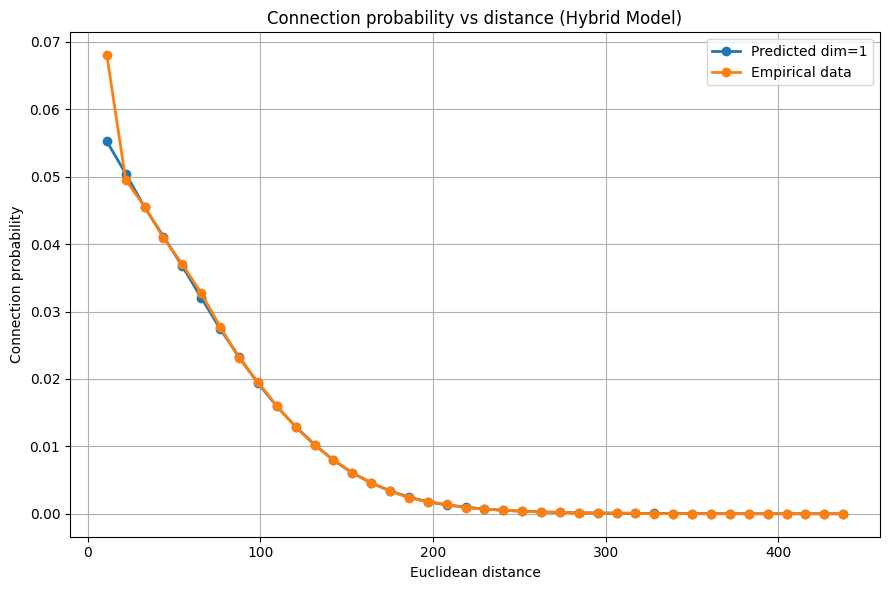

dim=1 corr=-0.004


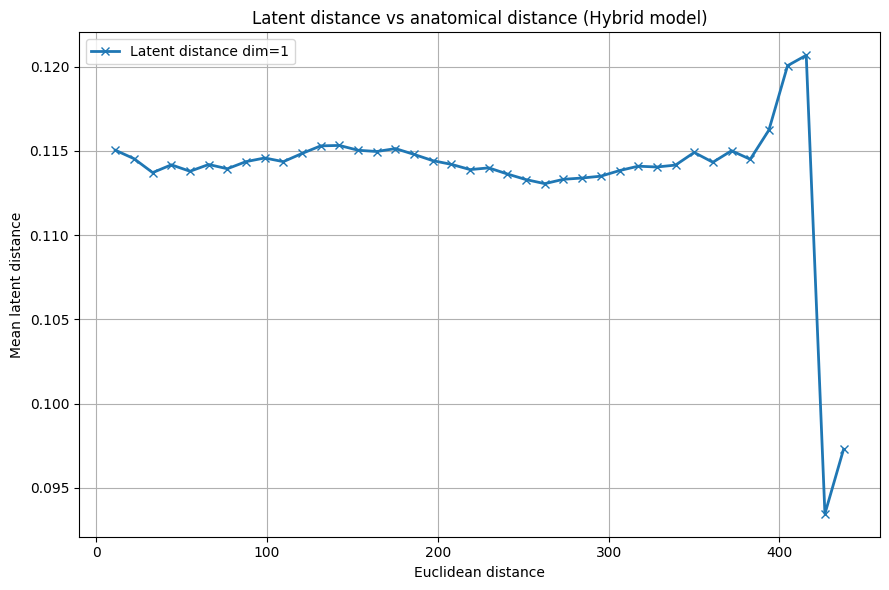

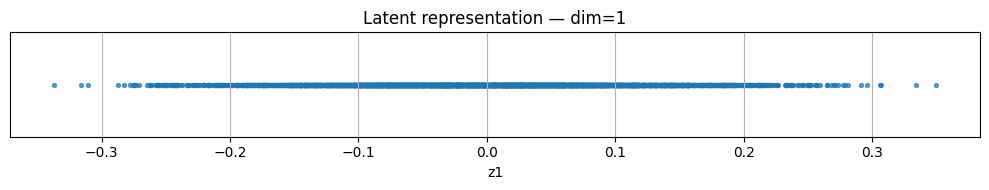

In [ ]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


DIMS_TO_ANALYZE = [1]
N_BINS = 40
BATCH_SIZE = 32768


# ============================================================
# 1. Pair ids and Euclidean distances
# ============================================================

idx_to_id = np.array(all_ids)

pre_idx_np = pre_idx.cpu().numpy() if torch.is_tensor(pre_idx) else pre_idx
post_idx_np = post_idx.cpu().numpy() if torch.is_tensor(post_idx) else post_idx

pre_ids = idx_to_id[pre_idx_np]
post_ids = idx_to_id[post_idx_np]

pos = units_cleaned.set_index("pt_root_id")[
    ["pt_position_x", "pt_position_y", "pt_position_z"]
]

pre_pos = pos.loc[pre_ids].values
post_pos = pos.loc[post_ids].values

distance = np.linalg.norm(
    pre_pos - post_pos,
    axis=1
)

y_emp = y.cpu().numpy() if torch.is_tensor(y) else y


# ============================================================
# 2. Common distance bins
# ============================================================

distance_bins = np.linspace(
    distance.min(),
    distance.max(),
    N_BINS + 1
)

distance_bin = pd.cut(
    distance,
    bins=distance_bins,
    include_lowest=True
)

bin_centers = np.array([
    b.mid for b in distance_bin.categories
])


# ============================================================
# 3. Empirical curve
# ============================================================

df_emp = pd.DataFrame({
    "distance": distance,
    "y": y_emp,
    "distance_bin": distance_bin,
})

emp_curve = (
    df_emp
    .groupby("distance_bin")
    .agg(
        empirical_prob=("y", "mean"),
        n_pairs=("y", "size"),
        n_connections=("y", "sum"),
    )
)


# ============================================================
# 4. Containers for all dimensions
# ============================================================

predicted_curves = {}
latent_curves = {}
latent_spaces = {}


# ============================================================
# 5. Loop over dimensions
# ============================================================

for dim in DIMS_TO_ANALYZE:

    print("\n========================")
    print(f"Analyzing dim = {dim}")
    print("========================")

    ckpt_path = os.path.join(
        CHECKPOINT_DIR,
        f"best_dim_{dim}.pt"
    )

    
    model = VisibilityAwareEmbeddingModel(
        n_neurons=n_neurons,
        dim=dim,
        positions=positions,
        positions_um=positions_um,
        distance_mean=distance_mean,
        distance_std=distance_std,
        axon_features=axon_features,
        dendrite_features=dendrite_features,
        axon_fully_proofread=axon_fully_proofread,
        dendrite_fully_proofread=dendrite_fully_proofread,
    ).to(DEVICE)

    ckpt = torch.load(
        ckpt_path,
        map_location=DEVICE,
        weights_only=False
    )

    model.load_state_dict(
        ckpt["model_state_dict"]
    )

    model.eval()

    print(f"Loaded best epoch: {ckpt['best_epoch']}")
    print(f"Best val loss: {ckpt['best_val_loss']:.4f}")

    # --------------------------------------------------------
    # Extract latent space
    # --------------------------------------------------------

    with torch.no_grad():
        Z = model.Z.weight.detach().cpu().numpy()

    latent_spaces[dim] = Z

    # --------------------------------------------------------
    # Predict probabilities in batches
    # --------------------------------------------------------

    all_probs = []

    with torch.no_grad():

        for start in range(0, len(y_emp), BATCH_SIZE):

            end = start + BATCH_SIZE

            pi = torch.as_tensor(
                pre_idx_np[start:end],
                dtype=torch.long,
                device=DEVICE
            )

            pj = torch.as_tensor(
                post_idx_np[start:end],
                dtype=torch.long,
                device=DEVICE
            )

            p_batch = model(
                pi,
                pj
            ).detach().cpu().numpy()

            all_probs.append(p_batch)

    p_pred = np.concatenate(all_probs)

    # --------------------------------------------------------
    # Predicted probability by anatomical distance
    # --------------------------------------------------------

    df_pred = pd.DataFrame({
        "distance": distance,
        "y": y_emp,
        "p_pred": p_pred,
        "distance_bin": distance_bin,
    })

    curve_pred = (
        df_pred
        .groupby("distance_bin")
        .agg(
            predicted_prob=("p_pred", "mean"),
            n_pairs=("p_pred", "size"),
        )
    )

    predicted_curves[dim] = curve_pred

    # --------------------------------------------------------
    # Latent distance by anatomical distance
    # --------------------------------------------------------

    z_pre = Z[pre_idx_np]
    z_post = Z[post_idx_np]

    latent_distance = np.linalg.norm(
        z_pre - z_post,
        axis=1
    )

    df_latent = pd.DataFrame({
        "geo_distance": distance,
        "latent_distance": latent_distance,
        "distance_bin": distance_bin,
    })

    curve_latent = (
        df_latent
        .groupby("distance_bin")
        .agg(
            mean_latent_distance=("latent_distance", "mean"),
            std_latent_distance=("latent_distance", "std"),
            n_pairs=("latent_distance", "size"),
        )
    )

    latent_curves[dim] = curve_latent

    corr = np.corrcoef(
        distance,
        latent_distance
    )[0, 1]

    print(
        f"corr(geometrical distance, latent distance) = {corr:.3f}"
    )


# ============================================================
# 6. Plot empirical + predicted probability for all dimensions
# ============================================================

plt.figure(figsize=(9, 6))

for dim in DIMS_TO_ANALYZE:

    plt.plot(
        bin_centers,
        predicted_curves[dim]["predicted_prob"],
        marker="o",
        linewidth=2,
        label=f"Predicted dim={dim}"
    )

plt.plot(
    bin_centers,
    emp_curve["empirical_prob"],
    marker="o",
    linewidth=2,
    label="Empirical data"
)

baseline_curve = pd.read_csv(
        "baselines/geometry_mlp_probability_vs_distance.csv",
        index_col=0
    )

baseline_centers = np.array([
pd.Interval(left=float(s.split(",")[0][1:]),
            right=float(s.split(",")[1][:-1])).mid
for s in baseline_curve.index
])

"""plt.plot(
    baseline_curve["bin_center"],
    baseline_curve["predicted_prob"],
    marker="o",
    linestyle="--",
    label="Geometry MLP baseline"
)"""


plt.xlabel("Euclidean distance")
plt.ylabel("Connection probability")
plt.title("Connection probability vs distance (Hybrid Model)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 7. Plot latent distance vs anatomical distance for all dims
# ============================================================

plt.figure(figsize=(9, 6))

for dim in DIMS_TO_ANALYZE:

    plt.plot(
        bin_centers,
        latent_curves[dim]["mean_latent_distance"],
        marker="x",
        linewidth=2,
        label=f"Latent distance dim={dim}"
    )

    corr = np.corrcoef(
    distance,
    latent_distance
)[0,1]

print(
    f"dim={dim} "
    f"corr={corr:.3f}"
)

plt.xlabel("Euclidean distance")
plt.ylabel("Mean latent distance")
plt.title("Latent distance vs anatomical distance (Hybrid model)")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 8. Latent representation dim = 1
# ============================================================

Z1 = latent_spaces[1]

plt.figure(figsize=(10, 2))

plt.scatter(
    Z1[:, 0],
    np.zeros(len(Z1)),
    s=8,
    alpha=0.7
)

plt.xlabel("z1")
plt.yticks([])
plt.title("Latent representation — dim=1")

plt.grid(True)
plt.tight_layout()
plt.show()


"""# ============================================================
# 9. Latent representation dim = 2
# ============================================================

Z2 = latent_spaces[2]

plt.figure(figsize=(7, 7))

plt.scatter(
    Z2[:, 0],
    Z2[:, 1],
    s=8,
    alpha=0.7
)

plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Latent representation — dim=2")

plt.axis("equal")
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# 10. Latent representation dim = 3
# ============================================================

Z3 = latent_spaces[3]

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    Z3[:, 0],
    Z3[:, 1],
    Z3[:, 2],
    s=8,
    alpha=0.7
)

ax.set_xlabel("z1")
ax.set_ylabel("z2")
ax.set_zlabel("z3")
ax.set_title("Latent representation — dim=3")

plt.tight_layout()"""
plt.show()

In [ ]:
# ============================================================
# Save 3D geometry + proofreading baseline
# ============================================================

REFERENCE_DIM = 1

os.makedirs(
    "baselines",
    exist_ok=True
)

reference_curve = predicted_curves[
    REFERENCE_DIM
]

intervals = reference_curve.index

baseline_to_save = pd.DataFrame({
    "bin_left": [
        interval.left
        for interval in intervals
    ],

    "bin_right": [
        interval.right
        for interval in intervals
    ],

    "bin_center": bin_centers,

    "predicted_prob": (
        reference_curve["predicted_prob"]
        .to_numpy()
    ),

    "empirical_prob": (
        emp_curve["empirical_prob"]
        .to_numpy()
    ),

    "n_pairs": (
        emp_curve["n_pairs"]
        .to_numpy()
    ),

    "n_connections": (
        emp_curve["n_connections"]
        .to_numpy()
    ),
})


baseline_path = os.path.join(
    "baselines",
    "3d_geo_with_proofread_information_baseline.csv"
)

baseline_to_save.to_csv(
    baseline_path,
    index=False
)

print(
    "Baseline saved:",
    baseline_path
)

display(
    baseline_to_save.head()
)